# EDA: AI Employment Impact

*Josh Duchene — SEIS 631*


The goal of this project is to examine the relationship between exposure to AI and changes in employment, by occupation, in the US. This analysis is being conducted using BLS (Bureau of Labor Statistics) data.

The general question I'll be testing is this: Have occupations that are highly exposed to AI seen greater (or lesser) changes in total employment over the past few years compared to occupations that are less exposed, or is there no difference between those with higher/lower exposure?

## 1. Provenance & scope

1. I got the data from the BLS website.

    These are the data sources I plan to use:

    * https://www.bls.gov/emp/publications/ai-exposure-categories.htm

        gives the AI-exposure levels of the ~830 job categories included.

        The exposure ratings are Low, Moderate, High, and Very High. The website cites 5 scholarly articles that were used to informed this ranking. It seems like they did a pretty thorough job trying to come up with these ratings, but, it's obviously a bit speculative and subjective. But the BLS does survey actual businesses, so my assumption is essentially, who is more likely than the BLS to have gathered decent data/knowledge on how/where AI is currently being deployed.

        I read it into python as `ai_exposure_ratings`

    * https://www.bls.gov/oes/tables.htm

        This page has links to the Occupational Employment and Wage Statistics (OEWS) Tables

        It has a file for each year, giving employment numbers, median wages, etc by job title. it has 830 job titles, and each of those has an industry code, (e.g 12-3456), where each digit provides a more detailed breakdown, meaning I will be able to group/aggregate the data to a more useful level, while still having access to the lower level data. The data downloads actually include rows for these aggregated values as well, so when I use the data, I end up filtering it to only include rows at the lowest level.

        It has data for each year, but I only use 2022 and 2025. I chose 2025 because it's the latest year available, and I chose 2022 because Chat GPT became available to the public in Nov. 2022, so May 2022 seems like a good 'before' point to use. 

        I read this data into python as `data_2022` and `data_2025`, and merge these together, creating `employment_data`

    <!-- * https://www.bls.gov/oes/2025/may/oes_stru.htm

        Gives the breakdown of the occupation codes, at the high level, and all subsequent lower levels. Here's the first few rows to give an idea:

            11-0000 Management Occupations

            11-1000 Top Executives

            11-1010 Chief Executives

            11-1011 Chief Executives

            11-1020 General and Operations Managers

            11-1021 General and Operations Managers

            11-1030 Legislators

            11-1031 Legislators

            11-2000 Advertising, Marketing, Promotions, Public Relations, and Sales Managers -->


2. Each row represents data for one occupational grouping. So, as a made up example, there might be a row for 'Data Scientists & Data Analysts', another row for 'Data Scientists', and another for 'Data Analysts'.

3. How big is it, and what time period / geography / population does it cover?

    The AI exposure dataset has 831 rows, and the employment dataset has 1400 rows after merging the 2022 and 2025 data, but this drops to 829 rows after filtering by aggregation level.


4. What could this data plausibly generalize to — and what tempting question can it *not* answer?

    This data comes from the BLS, and is meant to represent the totality of employment in the US. So in theory, it is already as general as it gets. I suppose it could be tempting to generalize to other countries, but the labor markets in different countries are very different, so I don't think that would be warranted. The AI exposure ratings are somewhat based on actual reported use of AI, but they're also somewhat speculative, so I suppose it could be tempting to assume these ratings are 100% correct, and that nothing in the AI landscape will change in the next few years.   


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Loading the data

First, I load in the employment data from the years 2022 and 2025. Once they're loaded in, I will merge the two datasets together.

In [2]:
def read_and_prepare_data(file_path, suffix=''):
    df = pd.read_csv(file_path, sep='\t')
    # Looking very breifly at a few things just to make sure the data was read in properly.
    assert df['AREA'].eq(99).all(), \
        'The data should only contain national-level entries, indicated by AREA equaling 99.'

    df['TOT_EMP'] = df['TOT_EMP'].str.replace(',', '').astype(int)

    cols_to_keep = ['OCC_CODE', 'OCC_TITLE', 'O_GROUP', 'TOT_EMP', 'EMP_PRSE']
    df = df[cols_to_keep]
    # renaming the columns to include the suffix for consistency with the year-specific data
    df = df.rename(columns={col: col + suffix for col in ['TOT_EMP', 'EMP_PRSE']})

    return df


data_2025 = read_and_prepare_data('data/national_M2025_dl.tsv', '_2025')
print('Shape of the 2025 data:', data_2025.shape)
display(data_2025.dtypes)

data_2022 = read_and_prepare_data('data/national_M2022_dl.tsv', '_2022')
print('Shape of the 2022 data:', data_2022.shape)


Shape of the 2025 data: (1401, 5)


OCC_CODE             str
OCC_TITLE            str
O_GROUP              str
TOT_EMP_2025       int64
EMP_PRSE_2025    float64
dtype: object

Shape of the 2022 data: (1402, 5)


# Merging the 2025 and 2022 data

Merging the two datasets on ['OCC_CODE', 'OCC_TITLE', 'O_GROUP']. In theory, merging on OCC_CODE alone is sufficient, but merging on all 3, and seeing that new rows don't end up getting created, serves as an implicit validation step, verifying that the categorization didn't change between 2022 and 2025.

The only other rows that we kept from the original datasets were the `TOT_EMP` and `EMP_PRSE` columns, so after the merge, we end up with 2 versions of these columns, 1 from each dataset.

In terms of the merge, the 2025 and 2022 datasets had 1401 and 1402 rows, and the merged outcome had 1403 rows.

1400 of the rows matched perfectly, and only 3 were unmatched.
* 2 rows were in the 2022 data, but not 2025
    - These rows were the 'legislators' category. For whatever reason, this occupation is just not listed in the 2025 data.
* 1 row was in the 2025 data, but not 2022:
    - This was the 'Prosthodontists' category, with ~900 total employment in the US.

With 1400 rows matched, and only 3 unmatched, it's fine for the analysis to simply drop the unmatched rows.

In [3]:
employment_data = pd.merge(
    data_2022,
    data_2025,
    on=['OCC_CODE', 'OCC_TITLE', 'O_GROUP'],
    how='outer',
    validate='one_to_one',
    indicator=True)

# print the shapes of the 2022 and 2025 data
print('Shape of the 2022 data:', data_2022.shape)
print('Shape of the 2025 data:', data_2025.shape)
print('Shape of the merged data:', employment_data.shape)
display(employment_data['_merge'].value_counts())

print('There are only 3 rows that do not match between the 2022 and 2025 data. '
      'They are shown below:')
display(employment_data[employment_data['_merge'] != 'both'])

# Drop the unmatched rows
employment_data = employment_data[employment_data['_merge'] == 'both'].drop(columns=['_merge'])
print('Shape of the data after dropping unmatched rows:', employment_data.shape)


Shape of the 2022 data: (1402, 5)
Shape of the 2025 data: (1401, 5)
Shape of the merged data: (1403, 8)


_merge
both          1400
left_only        2
right_only       1
Name: count, dtype: int64

There are only 3 rows that do not match between the 2022 and 2025 data. They are shown below:


,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP_2022,EMP_PRSE_2022,TOT_EMP_2025,EMP_PRSE_2025,_merge
7,11-1030,Legislators,broad,42890.0,2.1,NaN,NaN,left_only
8,11-1031,Legislators,detailed,42890.0,2.1,NaN,NaN,left_only
516,29-1024,Prosthodontists,detailed,NaN,NaN,870.0,27.6,right_only


Shape of the data after dropping unmatched rows: (1400, 7)


### Now, reading in the dataset with the AI Exposure ratings

In [4]:
cols_to_keep = [
    '2025 National Employment Matrix title',
    '2025 National Employment Matrix code',
    'Employment, 2025',
    'Relative AI exposure',
]

# The data came in an excel file, and when I saved it as a tsv file,
# all of the dashes were turned to this: �. And it was causing issues
# in pandas. So, I just made a copy of the file, and manually did replace
# all to change all of the � back to - .

ai_exposure_ratings = pd.read_csv(
    'data/ai-exposure-categories-fixed_encodings.tsv',
    sep='\t',
    skiprows=1,  # The first row is the title of the whole worksheet
    nrows=831,  # The rows beyond this are just a footnote
    usecols=cols_to_keep)

# Fixing the 'Employment, 2025' column to be numeric by removing commas and converting to float
# Additionally, the employment numbers are given in thousands,
#  so multiplying by 1000 to get the actual numbers
ai_exposure_ratings['Employment, 2025'] = (
    ai_exposure_ratings['Employment, 2025']
    .str.replace(',', '')
    .astype(float)
    * 1000
)

# Verifying that the total employment in 2025 is within the expected range
assert 1e8 <= ai_exposure_ratings['Employment, 2025'].sum() <= 2e8, \
    'Expected total employment in 2025 to be between 100 and 200 million'

display(ai_exposure_ratings.tail(10))

,2025 National Employment Matrix title,2025 National Employment Matrix code,"Employment, 2025",Relative AI exposure
821,"Laborers and freight, stock, and material move...",53-7062,2940300.0,Low
822,Machine feeders and offbearers,53-7063,41800.0,Low
823,"Packers and packagers, hand",53-7064,555500.0,Low
824,Stockers and order fillers,53-7065,2804300.0,Moderate
825,Gas compressor and gas pumping station operators,53-7071,3500.0,Low
826,"Pump operators, except wellhead pumpers",53-7072,9800.0,Moderate
827,Wellhead pumpers,53-7073,18400.0,Low
828,Refuse and recyclable material collectors,53-7081,156400.0,Low
829,"Tank car, truck, and ship loaders",53-7121,12800.0,Low
830,"Material moving workers, all other",53-7199,27800.0,Low


### Deciding on the level of aggregation for the analysis

So before digging too much further into the data itself, I need to decide what level of aggregation to do the analysis at. The occupation codes are given as 6 digit codes, and each subsequent digit adds a level of specificity. The AI exposure ratings are provided at the most detailed level, so I would be able to use the most granular data, or aggregate it up if the low-level data is too messy.


I was expecting it to be a deicison with no clear 'correct' answer, but, as it turns out, the decision is actually relatively easy to make. Essentially, if I were going to aggregate the data up a level, but the AI exposure ratings are at the lowest level, I'd need some way of deciding what label to assign to the new, aggregated groups. This would be easy if all of the occupations in a given group had the same labels, but it would be a lot more involved if there were mixed labels, and something I would only want to do if it was pretty rare for the labels to be mixed.

And so, in the next cell I look into this, to see how often there are mixed labels. And it turns out that about 20% of the aggregated groups would be created from occupations with mixed labels, and 40% of all occupations are in one of the groups with mixed labels. So that's a lot of information that I would basically be losing if I decided to go the aggregation route, so I'm going to be sticking with the lowest level for my analysis.

In [5]:
detailed = ai_exposure_ratings.copy()
# replacing the final digit of the code with a 0, to create a broad code
detailed["broad_code"] = detailed["2025 National Employment Matrix code"].str[:-1] + "0"

# how many distinct labels per broad group?
agreement = detailed.groupby("broad_code")["Relative AI exposure"].nunique().rename("n_labels")
print(agreement.value_counts())
percent_with_mixed = (agreement > 1).mean()
print("Percent of broad groups with mixed labels: "
      f"{percent_with_mixed:.2%}")
print()

# how many occupations fall into broad groups with mixed labels?
detailed = detailed.merge(agreement, on="broad_code")
print(detailed['n_labels'].value_counts())
percent_with_mixed = (detailed['n_labels'] > 1).mean()
print("Percent of occupations within broad groups with mixed labels: "
      f"{percent_with_mixed:.2%}")

display(detailed.query('n_labels > 1'))


n_labels
1    360
2     83
3     13
Name: count, dtype: int64
Percent of broad groups with mixed labels: 21.05%

n_labels
1    493
2    267
3     71
Name: count, dtype: int64
Percent of occupations within broad groups with mixed labels: 40.67%


,2025 National Employment Matrix title,2025 National Employment Matrix code,"Employment, 2025",Relative AI exposure,broad_code,n_labels
3,Marketing managers,11-2021,421600.0,Very high,11-2020,2
4,Sales managers,11-2022,650100.0,High,11-2020,2
5,Public relations managers,11-2032,80800.0,Very high,11-2030,2
6,Fundraising managers,11-2033,48800.0,High,11-2030,2
7,Administrative services managers,11-3012,279000.0,Moderate,11-3010,2
...,...,...,...,...,...,...
823,"Packers and packagers, hand",53-7064,555500.0,Low,53-7060,2
824,Stockers and order fillers,53-7065,2804300.0,Moderate,53-7060,2
825,Gas compressor and gas pumping station operators,53-7071,3500.0,Low,53-7070,2
826,"Pump operators, except wellhead pumpers",53-7072,9800.0,Moderate,53-7070,2


So now that I've decided I'm using the detailed occupational codes for the analysis, I need to filter `employment_data`, as this dataset includes rows for the aggregated occupation categories. The filtering itself is just 1 line of code, but I want to do a quick bit of EDA first to show that this approach is correct.

In [6]:
# EDA on aggregation levels

# the O_GROUP column shows the aggregation level in the data. 
# The possible values are total, major, minor, broad, or detailed.
display('Showing the value counts of O_GROUP')
display(employment_data['O_GROUP'].value_counts())

# Showing the total employment for each aggregation level. 
display('Showing the total 2025 employment for each of the O_GROUP levels.')
display('The main thing to notice is that they all essentially sum up to the same total.')
display(employment_data.groupby('O_GROUP')['TOT_EMP_2025'].sum())

display('Here is an example of one branch of the occupational hierarchy')
display('to help visualize how the aggregation levels work')
display(
    employment_data
    [['OCC_CODE', 'OCC_TITLE', 'O_GROUP', 'TOT_EMP_2025']]
    .query('OCC_CODE.str.startswith("11-20") or OCC_CODE.str.startswith("11-0000")')
)


'Showing the value counts of O_GROUP'

O_GROUP
detailed    829
broad       454
minor        94
major        22
total         1
Name: count, dtype: int64

'Showing the total 2025 employment for each of the O_GROUP levels.'

'The main thing to notice is that they all essentially sum up to the same total.'

O_GROUP
broad       155481690.0
detailed    155480970.0
major       155495730.0
minor       155494840.0
total       155495730.0
Name: TOT_EMP_2025, dtype: float64

'Here is an example of one branch of the occupational hierarchy'

'to help visualize how the aggregation levels work'

,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP_2025
1,11-0000,Management Occupations,major,11132700.0
9,11-2000,"Advertising, Marketing, Promotions, Public Rel...",minor,1167460.0
10,11-2010,Advertising and Promotions Managers,broad,21470.0
11,11-2011,Advertising and Promotions Managers,detailed,21470.0
12,11-2020,Marketing and Sales Managers,broad,1032320.0
13,11-2021,Marketing Managers,detailed,395240.0
14,11-2022,Sales Managers,detailed,637080.0
15,11-2030,Public Relations and Fundraising Managers,broad,113670.0
16,11-2032,Public Relations Managers,detailed,74850.0
17,11-2033,Fundraising Managers,detailed,38810.0


So the main thing to notice in the previous cell is that summing the employment numbers within each O_GROUP, we get the same number, and that number is ~155 million, which is what the total employment number in the US in May 2025 was. So this means we can choose whichever O_GROUP level we want, filter out the rest, and the resulting data will represent the overall employment in the US.

And since we are doing the analysis at the lowest level of aggregation, the O_GROUP we'll be using is 'detailed'.



In [7]:
detailed_employment_data = employment_data.query('O_GROUP == "detailed"').copy()
assert detailed_employment_data['O_GROUP'].eq('detailed').all(), \
    "Not all rows have O_GROUP equal to 'detailed'"

detailed_employment_data = detailed_employment_data.drop(columns=['O_GROUP'])
display(detailed_employment_data.head())

,OCC_CODE,OCC_TITLE,TOT_EMP_2022,EMP_PRSE_2022,TOT_EMP_2025,EMP_PRSE_2025
4,11-1011,Chief Executives,199240.0,0.9,204350.0,3.1
6,11-1021,General and Operations Managers,3376680.0,0.3,3503020.0,0.3
11,11-2011,Advertising and Promotions Managers,22010.0,3.1,21470.0,3.9
13,11-2021,Marketing Managers,328570.0,1.1,395240.0,0.8
14,11-2022,Sales Managers,536390.0,2.8,637080.0,1.1


### Merging the 2 datasets

Now, with both datasets being at the same level of aggregation, we merge them together.

There are 829 rows in the detailed_employment_data, and 831 in the ai_exposure_ratings. When I merge the 2 datasets, all 829 rows match up, with the 2 extra rows remaining unmatched. I simply drop these 2 rows.

And then to validate the merge, I verify that the occupation labels from the two datasets match, and I verify that the 2025 employment numbers from the 2 datasets roughly match. And for the most part, they do align very well. There are a few outliers, but since the two measurements don't come from the same source, and might not even have been measured at the same point in 2025, so we would expect some discrepancies.

In [8]:
print('Starting shape for detailed_employment_data:', detailed_employment_data.shape)
print('Starting shape for ai_exposure_ratings:', ai_exposure_ratings.shape)

merged_data = detailed_employment_data.merge(
    ai_exposure_ratings,
    left_on='OCC_CODE',
    right_on='2025 National Employment Matrix code',
    how='outer',
    validate='one_to_one',
    indicator=True,
)

# Only 2 rows didn't match in the merge, and they represented a very
# small portion of the data, so it's safe to just drop those 2 rows.
print('showing _merged value_counts, and the rows that did not match')
display(merged_data['_merge'].value_counts())
display(merged_data[merged_data['_merge'] != 'both'])
merged_data = merged_data[merged_data['_merge'] == 'both'].drop(columns=['_merge'])


# Validating the merge
assert (
    merged_data['OCC_TITLE'].str.lower()
    == merged_data['2025 National Employment Matrix title'].str.lower()
).all(), "OCC_TITLE and 2025 National Employment Matrix title do not match"


# Getting an absolute percent difference between Employment, 2025 and TOT_EMP_2025
# `Employment, 2025` comes from the AI exposure dataset, and I'm not planning on using
#  it in the analysis. But, I still want to check to make sure it's roughly consistent 
# with TOT_EMP_2025 from the employment dataset, as a further validation step,
#  to confirm that am I merging the datasets correctly

# And looking at the distribution of the absolute percent difference, there are a few
#  outliers, but overall the absolute percent difference seems reasonable. The numbers
#  don't come from the same source, and might not even have been measured at the same
#  point in 2025, so we would expect some discrepancies.
merged_data['abs_percent_diff'] = (
    (merged_data['Employment, 2025'] - merged_data['TOT_EMP_2025']).abs()
     / merged_data[['TOT_EMP_2025', 'Employment, 2025']].mean(axis=1)
     * 100
)
print('Displaying absolute percent difference statistics between "Employment, 2025" and "TOT_EMP_2025":')
display(merged_data['abs_percent_diff'].describe())
merged_data = merged_data.drop(columns=['abs_percent_diff'])

# Dropping the redundant columns from the AI exposure dataset, now that the merge has been validated.
redundant_columns = [
    '2025 National Employment Matrix title',
    '2025 National Employment Matrix code',
    'Employment, 2025',
]
merged_data = merged_data.drop(columns=redundant_columns)

Starting shape for detailed_employment_data: (829, 6)
Starting shape for ai_exposure_ratings: (831, 4)
showing _merged value_counts, and the rows that did not match


_merge
both          829
right_only      2
left_only       0
Name: count, dtype: int64

,OCC_CODE,OCC_TITLE,TOT_EMP_2022,EMP_PRSE_2022,TOT_EMP_2025,EMP_PRSE_2025,2025 National Employment Matrix title,2025 National Employment Matrix code,"Employment, 2025",Relative AI exposure,_merge
308,NaN,NaN,NaN,NaN,NaN,NaN,Prosthodontists,29-1024,1000.0,Low,right_only
559,NaN,NaN,NaN,NaN,NaN,NaN,Fishing and hunting workers,45-3031,28200.0,Low,right_only


Displaying absolute percent difference statistics between "Employment, 2025" and "TOT_EMP_2025":


count    829.000000
mean      14.147606
std       25.483409
min        0.000000
25%        1.843462
50%        4.980152
75%       14.813017
max      196.730382
Name: abs_percent_diff, dtype: float64

## Structure & quality

5. What are the important variables, and what type is each (categorical, continuous, datetime, text, ID)?

    The most important variables are `TOT_EMP_2022`, `TOT_EMP_2025` (These are ints), and `Relative AI exposure` (which is a categorical feature, taking the values [Very high, High, Moderate, Low])

    I create the columns `TOT_EMP_pct_change` and `TOT_EMP_abs_pct_change` eventually, as the (absolute) percent change between employment in 2022 and 2025 within a given occupation. 

    The other columns are `OCC_CODE` and `OCC_TITLE`, which are just labels for the occupation, and `EMP_PRSE_2022` and `EMP_PRSE_2025`, where PRSE stands for percent relative standard error values, and represent the uncertainty of the employment estimate. 

6. What's missing — and if nothing, how do you know? Completeness is a claim that must be earned: "no missing values (verified)" is real communication work. If something *is* missing, does it have a pattern?

    I validate below that there are no missing values.

7. Are there duplicates, impossible values, or suspicious encodings (999s, "unknown", mixed units)?
    
    I validate below that there are no duplicates, either across the entire row, or in the columns `OCC_CODE` or `OCC_TITLE`. 

    I validate that the employment columns are always nonnegative, and that all values of relative ai exposure are in the expected set of values ([Very high, High, Moderate, Low]).

    And the fact that the two datasets were merged on OCC_CODE, and the OCC_TITLE values from the 2 datasets matched every single time is its own sort of validation of those values.

8. What variables did the author create or transform, and why?

    All of the variables come straight from the BLS, so none of the variables are really *created* beyond the sense that the BLS has internal processes to create their statistics.


#### Describing the columns in the datasets

In [9]:
# The table created in this cell shows a summary of the columns,
# showing their dtype, how many unique values there are, some examples
# of the types of values (for categorical cols), and the observed min
# and max for numerical columns.

# Add compact details to help classify and describe columns.
def summarize_columns(df):
    inventory = pd.DataFrame(index=df.columns)
    inventory.index.name = "column"
    inventory["pandas_dtype"] = df.dtypes.astype(str)
    inventory["distinct_values"] = df.nunique(dropna=True)
    inventory["examples_or_levels"] = [
        df[column].dropna().unique()[:5].tolist()
        for column in df.columns
    ]

    numeric_columns = df.select_dtypes(include="number").columns
    inventory["observed_min"] = None
    inventory["observed_max"] = None
    inventory.loc[numeric_columns, "observed_min"] = df[numeric_columns].min()
    inventory.loc[numeric_columns, "observed_max"] = df[numeric_columns].max()

    return inventory


# Showing the detailed_employment_data dataset
print('Showing a sample of the merged_data dataset')
display(merged_data.sample(5, random_state=42))
print('Showing a brief of summary of the columns in the merged_data dataset')
display(summarize_columns(merged_data.copy()))


Showing a sample of the merged_data dataset


,OCC_CODE,OCC_TITLE,TOT_EMP_2022,EMP_PRSE_2022,TOT_EMP_2025,EMP_PRSE_2025,Relative AI exposure
610,47-4090,Miscellaneous Construction and Related Workers,29880.0,5.5,28380.0,5.2,Moderate
458,39-4012,Crematory Operators,2930.0,10.8,2970.0,5.9,Moderate
290,27-3041,Editors,101430.0,1.4,91690.0,1.7,Very high
560,45-4011,Forest and Conservation Workers,6080.0,8.6,6050.0,6.4,Low
168,19-4061,Social Science Research Assistants,28720.0,1.6,30640.0,1.8,Very high


Showing a brief of summary of the columns in the merged_data dataset


,pandas_dtype,distinct_values,examples_or_levels,observed_min,observed_max
column,,,,,
OCC_CODE,str,829,"[11-1011, 11-1021, 11-2011, 11-2021, 11-2022]",None,None
OCC_TITLE,str,829,"[Chief Executives, General and Operations Mana...",None,None
TOT_EMP_2022,float64,809,"[199240.0, 3376680.0, 22010.0, 328570.0, 53639...",330.0,3640040.0
EMP_PRSE_2022,float64,125,"[0.9, 0.3, 3.1, 1.1, 2.8]",0.0,34.5
TOT_EMP_2025,float64,810,"[204350.0, 3503020.0, 21470.0, 395240.0, 63708...",220.0,4305810.0
EMP_PRSE_2025,float64,130,"[3.1, 0.3, 3.9, 0.8, 1.1]",0.0,35.0
Relative AI exposure,str,4,"[Very high, High, Moderate, Low]",None,None


### Validating the data

In [10]:
# validating the data

assert merged_data.notna().all(axis=None)

for col in ['OCC_CODE', 'OCC_TITLE']:
    assert merged_data[col].duplicated().sum() == 0, \
        'Duplicates present in column: ' + col
assert merged_data.duplicated().sum() == 0, 'Duplicates present in the merged data'


assert merged_data[['TOT_EMP_2022', 'TOT_EMP_2025']].ge(0).all(axis=None), \
    'Negative values present in TOT_EMP_2022 or TOT_EMP_2025'

assert merged_data['Relative AI exposure'].isin(['Very high', 'High', 'Moderate', 'Low']).all(), \
    'Invalid values present in Relative AI exposure'

print('Data validation completed successfully.')

Data validation completed successfully.


### Creating the percent change columns

In [11]:
# Creating the precent change column
merged_data['TOT_EMP_pct_change'] = (
    (merged_data['TOT_EMP_2025'] - merged_data['TOT_EMP_2022'])
    / merged_data['TOT_EMP_2022']
    * 100
)

# Creating an absolute percent change column
merged_data['TOT_EMP_abs_pct_change'] = merged_data['TOT_EMP_pct_change'].abs()


assert merged_data[['TOT_EMP_abs_pct_change', 'TOT_EMP_pct_change']].notna().all(axis=None), \
    'Missing values present in TOT_EMP_abs_pct_change or TOT_EMP_pct_change'

# I tried asserting that none of these values would be 0, assuming that it
# would be very unlikely. 2 of the 830 rows did report 0 change, however.
# It seems a bit odd and unlikely that this would happen by chance,
# but since it was just 2 rows, there's not something systematically going on,
# so it's really not a huge deal.

display(merged_data[merged_data[['TOT_EMP_abs_pct_change', 'TOT_EMP_pct_change']].eq(0).any(axis=1)])

,OCC_CODE,OCC_TITLE,TOT_EMP_2022,EMP_PRSE_2022,TOT_EMP_2025,EMP_PRSE_2025,Relative AI exposure,TOT_EMP_pct_change,TOT_EMP_abs_pct_change
258,25-9021,Farm and Home Management Educators,8220.0,2.7,8220.0,5.9,High,0.0,0.0
585,47-2132,"Insulation Workers, Mechanical",25660.0,5.0,25660.0,5.2,Moderate,0.0,0.0


## Distributions & relationships

9. What does each key variable look like — shape, center, spread, outliers? *Do this with plots, but then also with words; do the work of interpretation for your audience.*
10. What are the two or three most important relationships in the data, shown and interpreted?
11. What's surprising here — what didn't the author expect to find?

### Showing the key variables

##### Looking at `Relative AI Exposure`

We start by looking at the distribution of Relative AI Exposure ratings. And it becomes instantly clear that the 4 ratings all have essentially the same number of occurrences, so it appears as though the occupations were just ordinally ranked based on AI exposure, and partitioned into 4 quartiles.

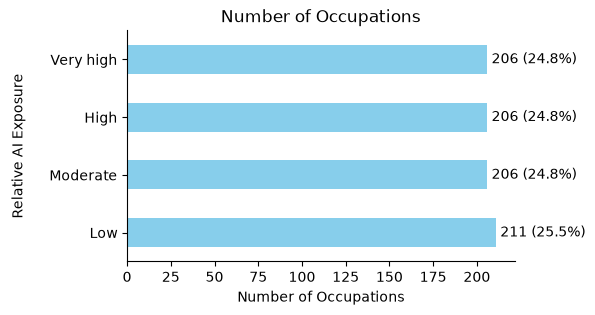

In [135]:
# plotting the distribution of Relative AI exposure among occupations
exposure_ordering = ['Very high', 'High', 'Moderate', 'Low']

plt.figure(figsize=(5, 3))
counts = merged_data['Relative AI exposure'].value_counts().loc[reversed(exposure_ordering)]
counts.plot(
    kind='barh',
    color='skyblue'
)
for i, (count, pct) in enumerate(zip(counts, counts / counts.sum() * 100)):
    plt.text(count + 0.1, i, f' {count} ({pct:.1f}%)', va='center')
plt.xlabel('Number of Occupations')
plt.ylabel('Relative AI Exposure\n')
plt.title('Number of Occupations')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

##### Looking at Total Employment Numbers

Now, we look at the Total employment numbers (`TOT_EMP_2022` and `TOT_EMP_2025`). They have very similar distributions (as we'd expect), and it's a heavy right-skewed distribution. (Again, the skew is expected, because some professions, e.g. teachers, have a very large number of people, while others are quite niche).

So I plot the distributions normally first to demonstrate the skew, and then remake the plots using a log10 scale.

With the log-scale plot, we see a roughly symmetrical, bell-shaped distribution.

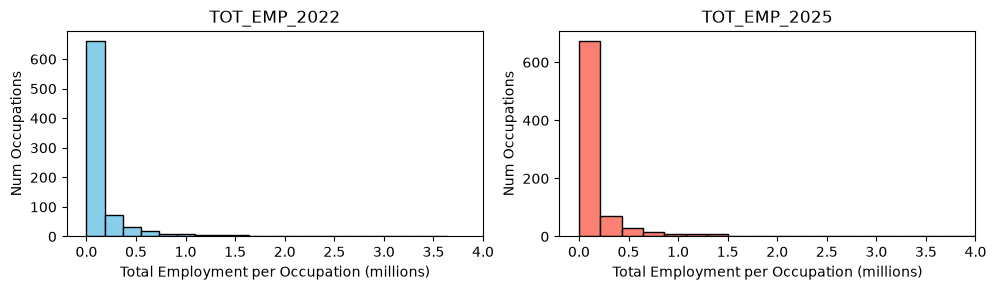

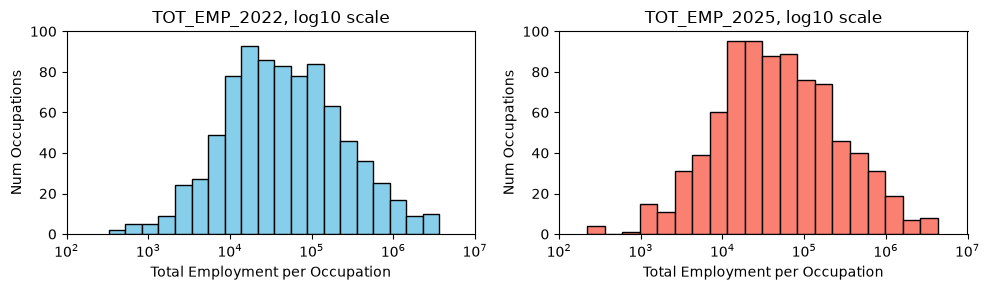

In [34]:
# make the plot again, but divide the values by 1 million first
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.hist(merged_data['TOT_EMP_2022'] / 1_000_000, bins=20, color='skyblue', edgecolor='black')
plt.xlim(-.2, 4)
plt.title('TOT_EMP_2022')
plt.xlabel('Total Employment per Occupation (millions)')
plt.ylabel('Num Occupations')

plt.subplot(1, 2, 2)
plt.hist(merged_data['TOT_EMP_2025'] / 1_000_000, bins=20, color='salmon', edgecolor='black')
plt.xlim(-.2, 4)
plt.title('TOT_EMP_2025')
plt.xlabel('Total Employment per Occupation (millions)')
plt.ylabel('Num Occupations')

plt.tight_layout()
plt.show()


# Plotting them on a log10 scale
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.hist(np.log10(merged_data['TOT_EMP_2022']), bins=20, color='skyblue', edgecolor='black')
plt.ylim(0, 100)
plt.xlim(2, 7)
plt.xticks(range(2, 8), [f'$10^{i}$' for i in range(2, 8)])
plt.title('TOT_EMP_2022, log10 scale')
plt.xlabel('Total Employment per Occupation')
plt.ylabel('Num Occupations')

plt.subplot(1, 2, 2)
plt.hist(np.log10(merged_data['TOT_EMP_2025']), bins=20, color='salmon', edgecolor='black')
plt.ylim(0, 100)
plt.xlim(2, 7)
plt.xticks(range(2, 8), [f'$10^{i}$' for i in range(2, 8)])
plt.title('TOT_EMP_2025, log10 scale')
plt.xlabel('Total Employment per Occupation')
plt.ylabel('Num Occupations')

plt.tight_layout()
plt.show()


#### To get a little more context, I also wanted to look at some of the largest and smallest occupations

In [83]:
# show the top 5 and bottom 5 occupations by the total employment in 2025
print('Showing the 5 occupations with the highest total employment in 2025')
display(merged_data[['OCC_TITLE', 'TOT_EMP_2025']].sort_values(by='TOT_EMP_2025', ascending=False).head(5))
print('Showing the 5 occupations with the lowest total employment in 2025')
display(merged_data[['OCC_TITLE', 'TOT_EMP_2025']].sort_values(by='TOT_EMP_2025', ascending=True).head(5))

Showing the 5 occupations with the highest total employment in 2025


,OCC_TITLE,TOT_EMP_2025
375,Home Health and Personal Care Aides,4305810.0
481,Retail Salespersons,3897860.0
426,Fast Food and Counter Workers,3854050.0
1,General and Operations Managers,3503020.0
324,Registered Nurses,3379720.0


Showing the 5 occupations with the lowest total employment in 2025


,OCC_TITLE,TOT_EMP_2025
738,"Patternmakers, Wood",220.0
683,Timing Device Assemblers and Adjusters,250.0
737,"Model Makers, Wood",280.0
44,Farm Labor Contractors,310.0
149,Industrial-Organizational Psychologists,790.0


##### Looking at `TOT_EMP_pct_change` and `TOT_EMP_abs_pct_change`

These distributions are right-skewed (especially the absolute value version). There are also a few pretty extreme outliers, that make the skew even more dramatic. The plots below are made without specifying the x-axis limits, so it's clear there are some major outliers that will need to be handled

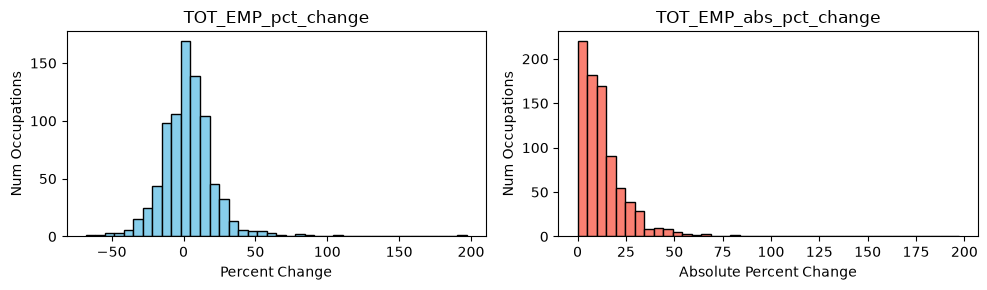

In [65]:
# make histograms of TOT_EMP_pct_change and TOT_EMP_abs_pct_change
# set the x axis limt to 75
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.hist(merged_data['TOT_EMP_pct_change'], bins=40, color='skyblue', edgecolor='black')
# plt.xlim(-75, 75)
plt.title('TOT_EMP_pct_change')
plt.xlabel('Percent Change')
plt.ylabel('Num Occupations')

plt.subplot(1, 2, 2)
plt.hist(merged_data['TOT_EMP_abs_pct_change'], bins=40, color='salmon', edgecolor='black')
# plt.xlim(-3, 75)
plt.title('TOT_EMP_abs_pct_change')
plt.xlabel('Absolute Percent Change')
plt.ylabel('Num Occupations')

plt.tight_layout()
plt.show()

Again, to get a little more context, I wanted to look at some of the top and bottom occupations in terms of largest absolute percent changes in employment


In [203]:
print('Showing the 5 occupations with the highest absolute percent change in employment')
display(merged_data.sort_values(by='TOT_EMP_abs_pct_change', ascending=False)[['OCC_TITLE', 'TOT_EMP_pct_change', 'TOT_EMP_2022', 'TOT_EMP_2025']].head(5))
print('Showing the 5 occupations with the lowest absolute percent change in employment')
display(merged_data.sort_values(by='TOT_EMP_abs_pct_change', ascending=True)[['OCC_TITLE', 'TOT_EMP_pct_change', 'TOT_EMP_2022', 'TOT_EMP_2025']].head(5))

Showing the 5 occupations with the highest absolute percent change in employment


,OCC_TITLE,TOT_EMP_pct_change,TOT_EMP_2022,TOT_EMP_2025
795,Taxi Drivers,197.033285,13820.0,41050.0
813,Passenger Attendants,105.378788,13200.0,27110.0
658,"Refractory Materials Repairers, Except Brickma...",86.206897,580.0,1080.0
490,Models,82.608696,2070.0,3780.0
420,"Cooks, Private Household",80.327869,610.0,1100.0


Showing the 5 occupations with the lowest absolute percent change in employment


,OCC_TITLE,TOT_EMP_pct_change,TOT_EMP_2022,TOT_EMP_2025
585,"Insulation Workers, Mechanical",0.000000,25660.0,25660.0
258,Farm and Home Management Educators,0.000000,8220.0,8220.0
758,"Extruding, Forming, Pressing, and Compacting M...",0.051073,58740.0,58770.0
251,Tutors,0.051434,174980.0,175070.0
534,"Production, Planning, and Expediting Clerks",0.061551,389920.0,390160.0


It's unsurprising that 3 of the 5 occupations with the largest percent changes were occupations with relatively small total employment, but the two with the largest are decent sized. Taxi drivers in particular is quite unexpected, as I would have assumed they were, if anything, in decline, as uber and lyft continue to take over. So this makes me think that it's more likely that somehow the classification of who counts as a taxi driver changed between 2022 and 2025, perhaps starting to count full-time uber/lyft drivers, or something like that.

There's no way to really know with the data we have, and it's probably not worth digging into it more deeply, but it does just add one more caveat to any conclusions we might draw, where the occupation categories might all be named the same things, but how people are apportioned might change somewhat. All that said, given how many of the occupations saw only incremental change between 2022 and 2025, it doesn't seem like this is something that occurs all that often, and it's probably not a huge concern to the analysis.

#### Deciding how to handle the outliers

Even though the data comes from the BLS, and therefore is likely all pretty reliable, outliers can still end up skewing the results, and causing misleading conclusions.

So the next few cells are me trying to decide how to handle them.

First, I simply look at the values of various percentiles to get a sense of how much of the data is actually taking these extreme values. And as we can see, the highest value is a nearly 200% increase, while the 98th percentile is only 50%.  

In [204]:
# Looking at the distributions of the percent change columns
display(
    merged_data
    [['TOT_EMP_pct_change', 'TOT_EMP_abs_pct_change']]
    .describe(percentiles=[.05, .1, .25, .5, .75, .9, .95, .98])
)

,TOT_EMP_pct_change,TOT_EMP_abs_pct_change
count,829.000000,829.000000
mean,3.145392,13.288609
std,18.985722,13.912681
min,-68.055556,0.000000
5%,-24.683354,1.007234
10%,-16.818133,2.112503
25%,-7.221845,4.704938
50%,2.958904,10.108765
75%,12.012645,16.925734
90%,22.750426,27.792300


### Exploring the outliers, using various cutoffs

So the general idea of this next cell is to explore how many observations fall above certain percent change cutoffs, and to get a sense of whether the extreme outliers all tended to be small occupations, where a small change in absolute numbers could result in a large percent change.

My general takeaway is that most occupations showed relatively incremental change, with the 5th and 95th percentiles being roughly +/- 25% change. So I feel like it makes sense to just set those as caps, and just clip any values above that.

As I look at the numbers, there are 107/829 (12.9%) occupations with an absolute percent change over 25%, only 17/829 (2.1%) over 50%, and 5/829 (0.6%) above 75%, 50% seems like a reasonable cutoff. Additionally, looking at the descriptive stats of the occupations above each of those cutoffs, we see the average size of the occupations above the cutoff shrink rapidly, implying that as the outliers become more extreme, it is increasingly likely that it's happening in small occupations where a relatively small absolute change represents a huge percent change. And this makes treating them as outliers seem even more reasonable.

That said, because the PRSE (percent relative standard error) values, which represent the uncertainty of the employment estimate, is still actually pretty small (usually < 5%), even for the major outliers, that implies that these large changes are probably actually real, and not just flukes of the data. So that pushes me in the direction of still including them in the dataset, but just clipping their values at 50%.

In [205]:
# exploring the outliers, using various cutoffs
for cutoff in [25, 50, 75]:
    print('If using the cutoff of +/- {}%:'.format(cutoff))
    display(
        merged_data[['TOT_EMP_2022', 'EMP_PRSE_2022']]
        .groupby(
            merged_data['TOT_EMP_abs_pct_change']
            .gt(cutoff)
            .rename('Above Cutoff')
        )
        .agg(['count', 'mean', 'median'])
        .drop(columns=[('EMP_PRSE_2022', 'count'), ('EMP_PRSE_2022', 'median')])
    )

If using the cutoff of +/- 25%:


TOT_EMP_2022                         EMP_PRSE_2022
                    count           mean   median          mean
Above Cutoff                                                   
False                 722  193601.454294  47660.0      2.968698
True                  107   75342.242991  16920.0      5.127103

If using the cutoff of +/- 50%:


TOT_EMP_2022                         EMP_PRSE_2022
                    count           mean   median          mean
Above Cutoff                                                   
False                 812  181456.366995  44980.0      3.152833
True                   17   29370.588235  11110.0      7.758824

If using the cutoff of +/- 75%:


TOT_EMP_2022                         EMP_PRSE_2022
                    count           mean   median          mean
Above Cutoff                                                   
False                 824  179382.997573  43610.0       3.18932
True                    5    6056.000000   2070.0      12.80000

#### Creating the clipped versions of the percent change columns

In [206]:
# create clipped versions of the percent change columns
merged_data['TOT_EMP_pct_change_clipped'] = \
    merged_data['TOT_EMP_pct_change'].clip(lower=-50, upper=50)
merged_data['TOT_EMP_abs_pct_change_clipped'] = \
    merged_data['TOT_EMP_abs_pct_change'].clip(lower=0, upper=50)

# add some assertions to verify that the checks below would have
# failed for the nonclipped versions
assert not merged_data['TOT_EMP_pct_change'].between(-50, 50).all()
assert not merged_data['TOT_EMP_abs_pct_change'].between(0, 50).all()
# add some assertions to verify the clipping worked correctly
assert merged_data['TOT_EMP_pct_change_clipped'].between(-50, 50).all()
assert merged_data['TOT_EMP_abs_pct_change_clipped'].between(0, 50).all()

# A note:
# I had tried adding an assertion to make sure only 17 values equal 50% in the
# clipped absolute percent change column, because 17 is the expected number
# of clipped values. but there were actually 18, because apparently the occupation
# 'Rail Transportation Workers, All Other' had employment numbers of 2240 and 1120
# in 2022 and 2025 respectively, meaning it had a percent change of exactly -50%.
# So, this doesn't really affect anything, but it's just worth noting I guess.

# # assert (merged_data['TOT_EMP_abs_pct_change_clipped'] == 50).sum() == 17


#### Plotting the newly-created clipped percent change columns

The distributions after clipping the outliers look a lot better. The Percent Change distribution is roughly bell-shaped, with its mean slightly above 0. And the Absolute Percent Change distribution is clearly right-skewed, but not so dramatically that we'd need to plot it on a log scale to see what's going on.

The other obvious thing is the large spike at 50%, which is expected, because all of the clipped outliers end up in that single bin.

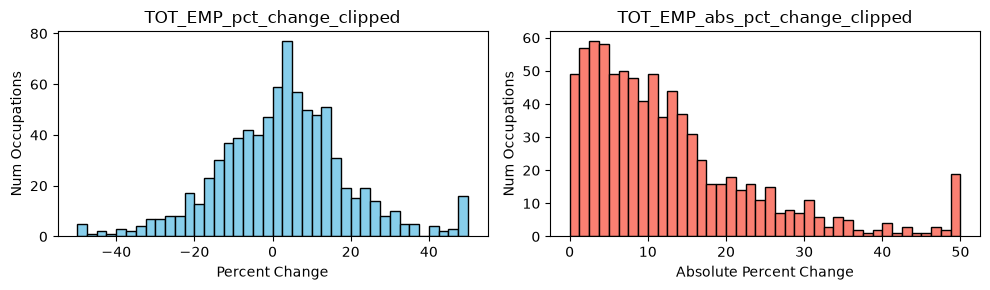

,TOT_EMP_pct_change_clipped,TOT_EMP_abs_pct_change_clipped
count,829.000000,829.000000
mean,2.736373,12.806113
std,16.714017,11.075223
min,-50.000000,0.000000
25%,-7.221845,4.704938
50%,2.958904,10.108765
75%,12.012645,16.925734
max,50.000000,50.000000


In [207]:
# change the pltos to use the clipped versions of the columns
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.hist(merged_data['TOT_EMP_pct_change_clipped'], bins=40, color='skyblue', edgecolor='black')
# plt.xlim(-75, 75)
plt.title('TOT_EMP_pct_change_clipped')
plt.xlabel('Percent Change')
plt.ylabel('Num Occupations')

plt.subplot(1, 2, 2)
plt.hist(merged_data['TOT_EMP_abs_pct_change_clipped'], bins=40, color='salmon', edgecolor='black')
# plt.xlim(-3, 75)
plt.title('TOT_EMP_abs_pct_change_clipped')
plt.xlabel('Absolute Percent Change')
plt.ylabel('Num Occupations')

plt.tight_layout()
plt.show()

# Show .describe for the clipped columns
display(
    merged_data[['TOT_EMP_pct_change_clipped', 'TOT_EMP_abs_pct_change_clipped']]
    .describe()
)

## Preregistering My Planned Analysis

So the next step in my EDA is starting to look at the relationships between the variables.

And this portion of the EDA is where it could become very easy to see how the `Relative AI Exposure` ratings relate to the other variables, and end up using that knowledge to choose how to set up my future analysis in a way that maximizes the liklihood of me finding something. So I want to unofficially pre-register my planned analysis here, along with my reasoning, before actually delving into the EDA

* I've already decided that I'm going to be using the absolute percent change, instead of the signed version, as my key variable, because it would be expected that in occupations affected by AI, some would increase, while others would decrease, and those are both meaningful changes. And so I don't want to use the signed version, because then large increases and large decreases would just average each other out, and look like there was no effect.

* In terms of the AI Exposure categories I'm comparing, my plan is run 2 comparisons as my analysis:
    - Very High vs (all else)
    - Very High vs Low

    My reasoning for choosing these 2 tests is as follows:
    
    - Before looking at the data, my thoughts are that, in theory, very high vs low should be the starkest comparison. That is, if we see a difference at all, this is where we'd be most likely to see it.

    - But I'm also thinking that, since there's been a huge increase in data center production, and a lot of those manufacturing jobs are likely to be rated as having 'low exposure', that sector might actually be seeing a large increase right now. And, I guess maybe it's an open question of whether that'll be sustained growth, or merely transitory, like just until they've built enough. So, all that to say, I'm also planning to run another comparison where I combine the 3 lower categories together, and compare that to the 'Very High' exposure group, to help mitigate any effect this might have.

    - I'm planning to stick with just those 2 comparisons, unless the data makes it very clear that I need to revise. I could obviously make comparisons of like the top 2 and the bottom 2, or any other combination, but that would easily lead to the multiple hypothesis testing issue, and also just an interpretation blackhole (e.g. what would it mean if the top 3 saw greater change than the bottom 1, but the top 2 didn't see more change than the bottom 2, etc.).


### Looking at the relationships between the key variables


The key relationships between variables I'll want to look at are mostly centered around the Relative AI Exposure feature.

I'll want to compare `Relative AI Exposure` to `TOT_EMP_2025`, and to `TOT_EMP_abs_pct_change_clipped` and `TOT_EMP_pct_change_clipped`

I also want to just get a sense of what kinds of jobs are classified in each category, so I'm going to look at the largest occupations in each group

And I also want to compare `TOT_EMP_2025` and `TOT_EMP_abs_pct_change_clipped`. This one is less directly relevant to the eventual analysis, but since my analysis plan is to use `TOT_EMP_abs_pct_change_clipped` as the response variable, I'm curious to see if / to what extent smaller occupations do tend to show larger changes, because that would mean they would tend to have a larger influence on the outcome than larger occupations.



In [208]:
# show the .describe of merged_data, grouping by 
exposure_ordering = ['Very high', 'High', 'Moderate', 'Low']

# show the top 3 occupations by `TOT_EMP_2025` for each ai exposure level
for exposure in exposure_ordering:
    print(f"Top 3 occupations for {exposure} AI exposure:")
    top_3 = (
        merged_data
        .query('`Relative AI exposure` == @exposure')
        .sort_values('TOT_EMP_2025', ascending=False)
        [['OCC_TITLE', 'TOT_EMP_2025', 'Relative AI exposure']]
        .head(3)
    )
    display(top_3)
    print()


Top 3 occupations for Very high AI exposure:


,OCC_TITLE,TOT_EMP_2025,Relative AI exposure
481,Retail Salespersons,3897860.0,Very high
513,Customer Service Representatives,2595750.0,Very high
546,"Office Clerks, General",2464940.0,Very high



Top 3 occupations for High AI exposure:


,OCC_TITLE,TOT_EMP_2025,Relative AI exposure
1,General and Operations Managers,3503020.0,High
324,Registered Nurses,3379720.0,High
477,Cashiers,3089410.0,High



Top 3 occupations for Moderate AI exposure:


,OCC_TITLE,TOT_EMP_2025,Relative AI exposure
375,Home Health and Personal Care Aides,4305810.0,Moderate
426,Fast Food and Counter Workers,3854050.0,Moderate
824,Stockers and Order Fillers,2833810.0,Moderate



Top 3 occupations for Low AI exposure:


,OCC_TITLE,TOT_EMP_2025,Relative AI exposure
821,"Laborers and Freight, Stock, and Material Move...",2950280.0,Low
435,"Janitors and Cleaners, Except Maids and Housek...",2209760.0,Low
666,"Maintenance and Repair Workers, General",1529700.0,Low


### Showing descriptive stats of key variables, grouped by AI Exposure category

In [ ]:
exposure_ordering = ['Very high', 'High', 'Moderate', 'Low']

for col in ['TOT_EMP_2025', 'TOT_EMP_abs_pct_change_clipped', 'TOT_EMP_pct_change_clipped']:
    print(f"Column: {col}")
    desc = (
        merged_data
        .groupby('Relative AI exposure')
        [col].describe()
        .drop(columns=['min', 'max', 'count'])
        .loc[exposure_ordering]
    )
    display(desc.style.background_gradient(cmap='Greens', low=0, high=1).set_table_styles(
        [{'selector': 'thead', 'props': [('color', 'white')]},
         {'selector': 'tbody', 'props': [('color', 'white')]}]
    ))
    print("\n")

# display them all again, just without the coloring thing.
print('Just displaying the descriptive statistics without coloring, in case the coloring looks weird on github')
for col in ['TOT_EMP_2025', 'TOT_EMP_abs_pct_change_clipped', 'TOT_EMP_pct_change_clipped']:
    print(f"Column: {col}")
    desc = (
        merged_data
        .groupby('Relative AI exposure')
        [col].describe()
        .drop(columns=['min', 'max', 'count'])
        .loc[exposure_ordering]
    )
    display(desc)
    print("\n")

Column: TOT_EMP_2025


,mean,std,25%,50%,75%
Relative AI exposure,,,,,
Very high,238999.854369,468063.716038,29127.500000,74380.000000,208085.000000
High,186575.000000,450502.548927,15400.000000,40755.000000,145820.000000
Moderate,195976.941748,525748.509306,13042.500000,33745.000000,135525.000000
Low,130053.554502,328175.151134,10550.000000,27120.000000,101310.000000




Column: TOT_EMP_abs_pct_change_clipped


,mean,std,25%,50%,75%
Relative AI exposure,,,,,
Very high,11.648468,10.455087,3.895496,9.611734,15.777310
High,14.012844,12.279411,5.179369,10.288138,19.543609
Moderate,13.065786,11.184508,4.857379,10.144997,17.208292
Low,12.504669,10.233163,5.229954,10.596219,16.133306




Column: TOT_EMP_pct_change_clipped


,mean,std,25%,50%,75%
Relative AI exposure,,,,,
Very high,0.979708,15.642667,-7.624120,1.924780,10.084467
High,8.291340,16.703890,-1.455528,6.896984,17.096411
Moderate,3.002879,16.958168,-7.212838,3.624110,12.937511
Low,-1.232113,16.133929,-11.860949,1.377565,8.287129


... (2 outputs left out)



Column: TOT_EMP_abs_pct_change_clipped


,mean,std,25%,50%,75%
Relative AI exposure,,,,,
Very high,11.648468,10.455087,3.895496,9.611734,15.777310
High,14.012844,12.279411,5.179369,10.288138,19.543609
Moderate,13.065786,11.184508,4.857379,10.144997,17.208292
Low,12.504669,10.233163,5.229954,10.596219,16.133306




Column: TOT_EMP_pct_change_clipped


,mean,std,25%,50%,75%
Relative AI exposure,,,,,
Very high,0.979708,15.642667,-7.624120,1.924780,10.084467
High,8.291340,16.703890,-1.455528,6.896984,17.096411
Moderate,3.002879,16.958168,-7.212838,3.624110,12.937511
Low,-1.232113,16.133929,-11.860949,1.377565,8.287129


### Plotting the mean and median of key variables, grouped by Relative AI exposure

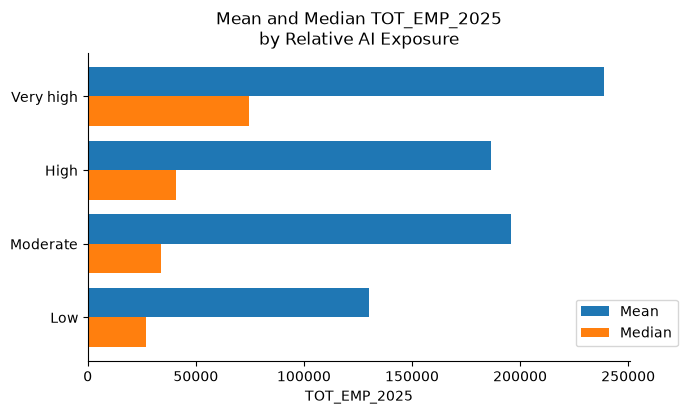

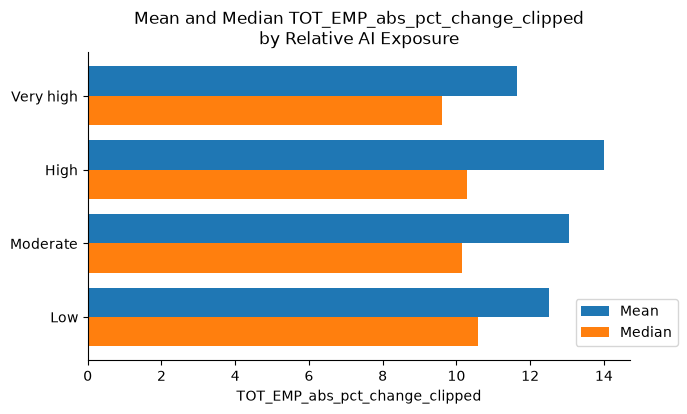

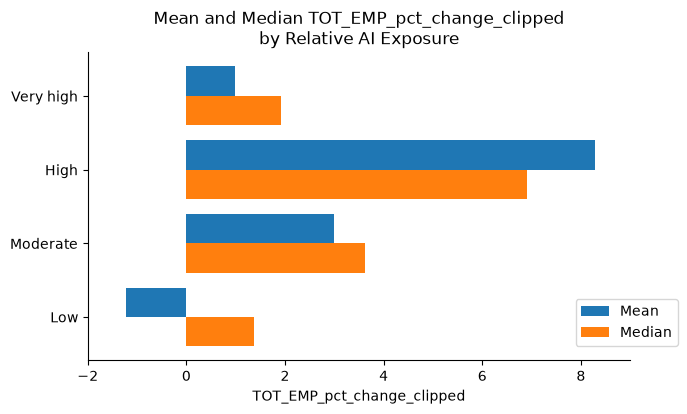

In [ ]:
exposure_ordering = ['Very high', 'High', 'Moderate', 'Low']

for col in ['TOT_EMP_2025', 'TOT_EMP_abs_pct_change_clipped', 'TOT_EMP_pct_change_clipped']:
    means = merged_data.groupby('Relative AI exposure')[col].mean().loc[reversed(exposure_ordering)]
    medians = merged_data.groupby('Relative AI exposure')[col].median().loc[reversed(exposure_ordering)]
    plt.figure(figsize=(7, 4))
    width = 0.4
    plt.barh([i + width/2 for i in range(len(medians))], means, height=width, label='Mean')
    plt.barh([i - width/2 for i in range(len(means))], medians, height=width, label='Median', left=0)
    plt.title(f"Mean and Median {col}\nby Relative AI Exposure")
    plt.xlabel(col)
    # plt.ylabel('Relative AI Exposure')
    plt.yticks([i for i in range(len(means))], means.index)
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.legend(loc='lower right', bbox_to_anchor=(1.1, 0.025))
    if col == 'TOT_EMP_pct_change_clipped':
        plt.xlim(-2, 9)

    plt.show()

So the main two takeaways from the plots are these:
1. The occupations in the 'Very high' category do tend to be quite a bit larger than those in the other categories.
2. There seems to be less change in the occupations with high exposure than those in other categories. This is kind of the exact opposite of what I had gone in thinking. The difference in occupation size between the exposure categories is large enough that I'm wondering if that's part of the explanation, or if there has just actually been less volatility in those groups.

## Readiness

12. If I wanted to run an analysis tomorrow, what would I still have to do to this data?

    The data is basically ready to go. Outliers have been handled, all columns needed for the analysis are already there,

13. What analyses is this dataset ready to support?

    It's ready to support permutation testing for the mean value of the `TOT_EMP_abs_pct_change_clipped`, or using bootstrapping to quantify the uncertainty of the estimates for each group.

## Other questions prompted by this dataset

Some of these questions were already raised and addressed earlier in the dataset.

The first one was about which level of granularity the analysis should be done at. And looking at the AI Exposure data set, it was clear that going up a level of aggregation would mean combining many occupations with different exposure ratings into the same group, and so I would be losing a lot of information by doing this.

Another question was just about verifying that the AI Exposure dataset and the historical employement data were being measured at the same level of granularity and classified the same way. I verified it by making sure it was a 1-to-1 merge, with no duplicates, and that the occupation labels matched after merging on the occupation codes. And I also verified that the employment numbers were at least within the same ballpark, to make sure I was understanding the data correctly.

The final question prompted sort of arose from my EDA earlier, where I noticed that the 'Very High' exposure group tended to have much larger occupations, and also saw less volatility than other categories. So I wanted to explore that relationship, to see if it was just that larger occupations tended to have less volatility, or if there seemed to be something systematic happening where occupations with very high exposure were seeing less volatility. I sort of briefly try to explore that below. and it paints a muddled picture. It might warrant a bit more digging, but nothing stands out immediately.

### Looking at abs percent change in employment by relative AI exposure, broken down by quartiles of total employment in 2025

I basically break the occupations into quartiles based on their total employment in 2025 and then look at the absolute percent change in employment by relative AI exposure within each quartile. So the goal is that I'll be comparing occupations of similiar sizes across the exposure categories, and thereby kind of controlling for the effect of occupation size on the observed changes.

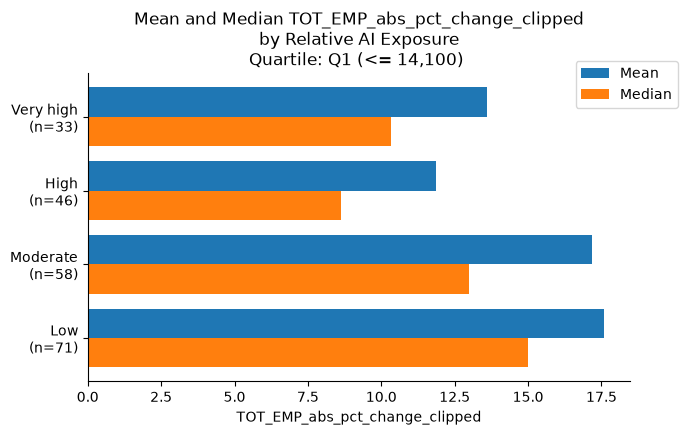

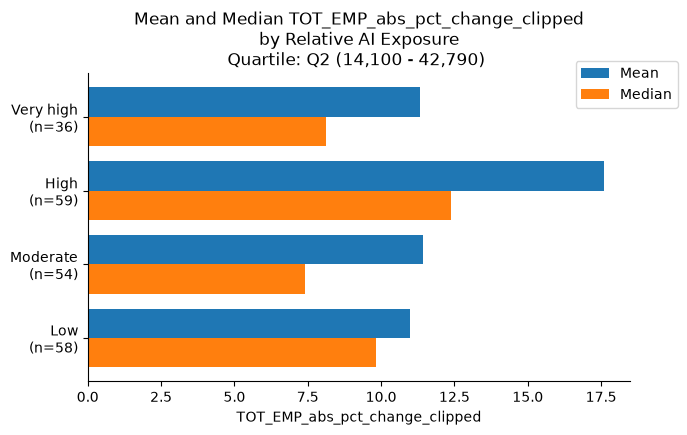

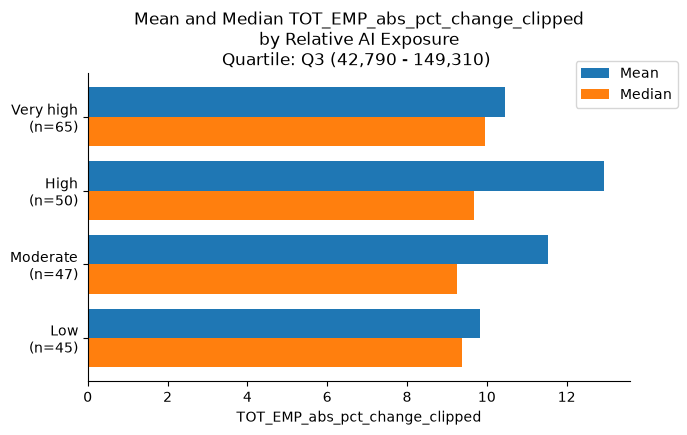

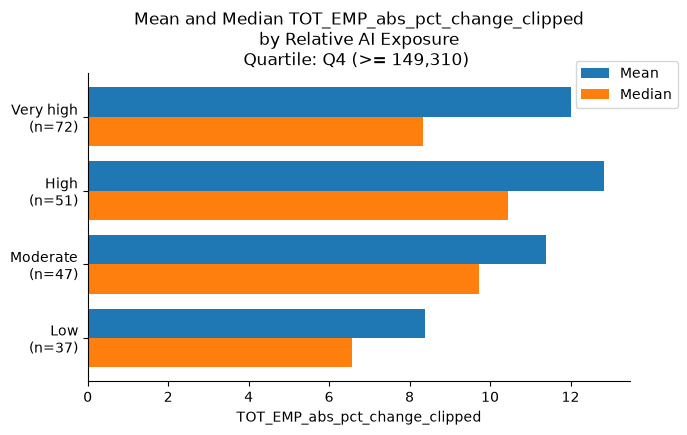

In [222]:
exposure_ordering = ['Very high', 'High', 'Moderate', 'Low']

# add the quartile cutoff points to the title of each plot
quartiles = merged_data['TOT_EMP_2025'].quantile([0.25, 0.5, 0.75])
quartile_labels = ['Q1', 'Q2', 'Q3', 'Q4']
merged_data['TOT_EMP_2025_quartile'] = pd.cut(
    merged_data['TOT_EMP_2025'],
    bins=[-float('inf')] + list(quartiles) + [float('inf')],
    labels=quartile_labels
)
for quartile in quartile_labels:
    filtered_data = merged_data[merged_data['TOT_EMP_2025_quartile'] == quartile]
    for col in ['TOT_EMP_abs_pct_change_clipped']:
        means = (filtered_data.groupby('Relative AI exposure')[col].mean()
                 .loc[reversed(exposure_ordering)])
        medians = (filtered_data.groupby('Relative AI exposure')[col].median()
                   .loc[reversed(exposure_ordering)])
        plt.figure(figsize=(7, 4))
        width = 0.4
        plt.barh([i + width/2 for i in range(len(medians))],
                  means, height=width, label='Mean')
        plt.barh([i - width/2 for i in range(len(means))],
                  medians, height=width, label='Median', left=0)
        # add the quartile cutoff points to the title of each plot
        quartile_cutoffs = {
            'Q1': f"<= {quartiles[0.25]:,.0f}",
            'Q2': f"{quartiles[0.25]:,.0f} - {quartiles[0.5]:,.0f}",
            'Q3': f"{quartiles[0.5]:,.0f} - {quartiles[0.75]:,.0f}",
            'Q4': f">= {quartiles[0.75]:,.0f}"
        }
        plt.title(f"Mean and Median {col}\nby Relative AI Exposure\nQuartile: "
                  f"{quartile} ({quartile_cutoffs[quartile]}) ")
        plt.xlabel(col)
        # add num observations for each Relative AI exposure category to the tick labels
        counts = (filtered_data.groupby('Relative AI exposure')[col].count()
                  .loc[reversed(exposure_ordering)])
        plt.yticks([i for i in range(len(means))],
                    [f"{idx}\n(n={counts[idx]})" for idx in means.index])
        plt.gca().spines['top'].set_visible(False)
        plt.gca().spines['right'].set_visible(False)
        plt.legend(loc='upper right', bbox_to_anchor=(1.1, 1.0625))
        # plt.legend(loc='lower right', bbox_to_anchor=(1.1, 0.025))
        plt.show()

# idk what below

count        454
mean      342470
std       683222
min          250
5%          5522
10%        10808
25%        32220
50%       102220
75%       327870
90%       834257
95%      1427969
max      6766670
Name: TOT_EMP, dtype: int64

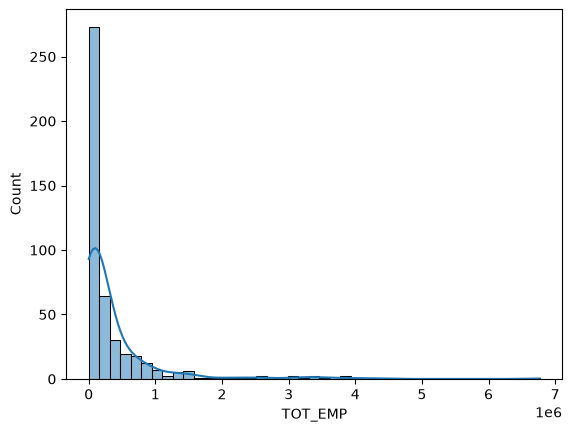

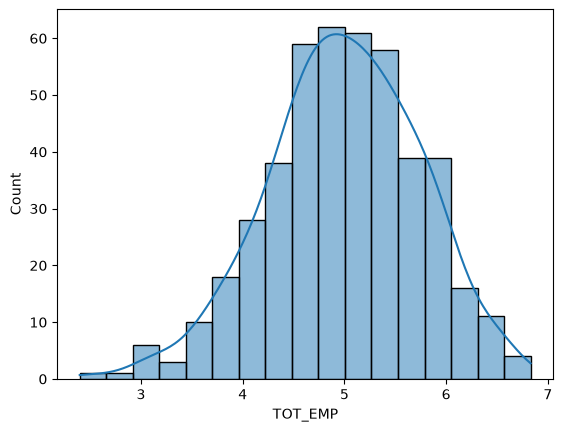

In [44]:
# repeat this, using the broad level

broad_2025 = data_2025.query('O_GROUP == "broad"')
display(broad_2025['TOT_EMP'].describe(percentiles=[.05, .1, .25, .5, .75, .9, .95]).astype(int))
# show a distplot
sns.histplot(broad_2025['TOT_EMP'], kde=True)
plt.show()

# show a distplot of tot_emp, log 10
sns.histplot(np.log10(broad_2025['TOT_EMP']), kde=True)
plt.show()
# So in terms of which level to use, the detailed level is the most granular, and gives us the most data points, so it would be the ideal candidate, assuming there aren't too many occupations at that level with tiny counts.


Which file to use?

I have 2025 employment numbers in the AI file itself, and in the Occupational Employment and Wage Statistics (OEWS) Table. I will be using the OEWS for the previous employment numbers, and so it makes sense for me to use the OEWS table for 2025 as well. A big benefit of this is that they both explicitly state that they are employment numbers for May, which means there's no seasoality concerns I'd have to deal with. 

However, since I theoretically do have the same kind of data, at the same level of granularity, in the AI exposure data set, and the OEWS table, it seems reasonable to at least compare the numbers, to make sure they're at least in the same level of magnitude. I'm not sure what it would mean if they're not, but it would warrant a little more digging into the data sources, to make sure I'm understanding their provenances correctly.

### Deciding which level of aggregation to use

Additional questions to address with this dataset specifically:

1. Does the 2025 OEWS data roughly align with the employment data from the AI Exposure file?
2. What level of aggregation should I do by occupation?
    - How many occupations actually do get broken down to the lowest level? (meaningfully, so not just having 4 levels that are all called the same thing)
    - For those that do get broken down, how small are the resulting employment numbers there?
    - How do I handle the really small ones? just move up a level of aggregation for those occupations? for all occupations? it seems like I would have to do it for all, so I'm comparing apples and oranges.
    - I'm wondering if it would make sense to look at the percent changes for some of these... basically the concern is, if thsese small occupations occasionally have like 100% changes, just because it's like 3,000 to 6,000, which could very easily just be a measurement error kind of thing, that could skew the data a lot
        - I'd need to be very careful to do this in a way where I don't end up making the decision based on what i'm seeing.
        - it might make sense to just basically calculate the percent differences for each, and then look at the distribution, and pick a reasonable upper/lower limit, and just cap values there.
    - For those at are broken down that much, do the AI exposure labels vary, or no? if they basically never do, rolling them up is an easy option if it makes the analysis cleaner. If they vary, and we do need to roll them up, is just treating the 4 labels as 1, 2, 3, 4, and getting the weighted average acceptable?
3. How am I doing the comparison? just, getting the absolute percent change for each occupation, and getting the average of those by category? an unweighted average? unweighted and standard weighting both seem not ideal... because either the most common jobs swamp the whole thing, or you end up with a bunch of tiny occupations representing like 75% of the volume, and 10% of the total employment... I'm wondering if logarithm/squareroot weighting is ever a thing... 
3. What categories am I actually comparing?
    Currently considering:
    - * Very High vs (all else)
    - * Very High vs Low

    Before looking at the data, my thoughts are that, in theory very high vs low should be the starkest comparison, where, if we see a difference at all, it would be there. but i'm also thinking that, since there's been a huge increase in data center production, a lot of those manufacturing jobs are likely to be rated as having 'low impact', and so that sector might actually be seeing a large increase right now, and I guess maybe it's an open question of whether that'll be sustained growth, or temporary, just until they've built enough. all that to say, combining the 3 lower categories together would help wash that effect out.

    I think i'm sticking with those 2 comparisons, unless the data makes it very clear that I need to revise. I could obviously make comparisons of like the top 2 and the bottom 2, or any other combination, but that would easily lead to the multiple hypothesis testing issue, and also just an interpretation blackhole.



In [105]:
cols_to_keep = [
    # '2025 National Employment Matrix title',
    '2025 National Employment Matrix code',
    'Employment, 2025',
    'Relative AI exposure',
]

# The data came in an excel file, and when I saved it as a tsv file,
# all of the dashes were turned to this: �. And it was causing issues
# in pandas. So, I just made a copy of the file, and manually did replace
# all to change all of the � back to - .

ai_df = pd.read_csv(
    'data/ai-exposure-categories-fixed_encodings.tsv',
    sep='\t',
    skiprows=1,  # The first row is the title of the whole worksheet
    nrows=831,  # The rows beyond this are just a footnote
    usecols=cols_to_keep)

ai_df['Employment, 2025'] = ai_df['Employment, 2025'].str.replace(',', '').astype(float)

ai_df.tail(10)

,2025 National Employment Matrix code,"Employment, 2025",Relative AI exposure
821,53-7062,2940.3,Low
822,53-7063,41.8,Low
823,53-7064,555.5,Low
824,53-7065,2804.3,Moderate
825,53-7071,3.5,Low
826,53-7072,9.8,Moderate
827,53-7073,18.4,Low
828,53-7081,156.4,Low
829,53-7121,12.8,Low
830,53-7199,27.8,Low


In [106]:
detailed = ai_df.copy()
detailed["broad_code"] = detailed["2025 National Employment Matrix code"].str[:6] + "0"

# how many distinct labels per broad group?
agreement = detailed.groupby("broad_code")["Relative AI exposure"].nunique()
print(agreement.value_counts())

detailed = detailed.merge(agreement.rename("n_labels"), on="broad_code")
print(detailed['n_labels'].value_counts())

display(detailed.query('n_labels > 1'))

# employment-weighted: what share of workers sit in broad groups with a single label?
print(detailed.groupby("n_labels")["Employment, 2025"].sum() / detailed["Employment, 2025"].sum())

Relative AI exposure
1    360
2     83
3     13
Name: count, dtype: int64
n_labels
1    493
2    267
3     71
Name: count, dtype: int64


,2025 National Employment Matrix code,"Employment, 2025",Relative AI exposure,broad_code,n_labels
3,11-2021,421.6,Very high,11-2020,2
4,11-2022,650.1,High,11-2020,2
5,11-2032,80.8,Very high,11-2030,2
6,11-2033,48.8,High,11-2030,2
7,11-3012,279.0,Moderate,11-3010,2
...,...,...,...,...,...
823,53-7064,555.5,Low,53-7060,2
824,53-7065,2804.3,Moderate,53-7060,2
825,53-7071,3.5,Low,53-7070,2
826,53-7072,9.8,Moderate,53-7070,2


n_labels
1    0.723816
2    0.230176
3    0.046008
Name: Employment, 2025, dtype: float64


In [3]:
# Looking at the top 5 rows of the dataset
display(sleep_data.head().iloc[:, :6])
display(sleep_data.head().iloc[:, 6:12])
display(sleep_data.head().iloc[:, 12:])

# Seeing no issues, we move on to the real EDA

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179
1,USR-00002,58,Female,Student,Intermediate,163
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27


,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min
0,Instagram / Reddit,54,1,0,21,84.4
1,YouTube,76,1,92,72,86.7
2,TikTok / Reels,59,0,45,23,70.5
3,YouTube,52,0,97,49,38.1
4,TikTok / Reels,82,1,0,38,32.3


,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,6.99,21.6,22.4,1,1.7,Mild Deficit
4,4.58,24.1,22.8,4,5.3,Moderate Debt


#### Looking for missing values

In [5]:
# The data set has no values being treated as missing by Pandas in any of the columns:
print('Num missing values in total: ', sleep_data.isna().sum().sum())

Num missing values in total:  0


So, there are no values that are technically missing.

But for the categorical features, it still could be possible that some of the values might be something like 'N/A', or some other string that's meant to represent missing data. So, because all of the categorical features have a relatively small number of unique values, it's easy enough to actually just look at all of the unique values for each feature, and verify that all of the values seem like real responses.

In [6]:
# Printing the unique values for each categorical column
print('Showing that the categorical columns have no suspicious missing value representations')
print()
# For columns that have fewer than 10 unique values, display the value_counts.
for col in sleep_data:
    if sleep_data[col].nunique() < 10:
        print(f'Value counts in column {col}:')
        display(sleep_data[col].value_counts(dropna=False))
        print()


Showing that the categorical columns have no suspicious missing value representations

Value counts in column gender:


gender
Female        4347
Male          3905
Non-Binary     248
Name: count, dtype: int64


Value counts in column occupation_type:


occupation_type
Corporate 9-to-5             2838
Remote Tech                  2142
Student                      1622
Healthcare / Shift Worker     997
Freelance / Creative          901
Name: count, dtype: int64


Value counts in column chronotype:


chronotype
Intermediate    3880
Night Owl       2455
Morning Lark    2165
Name: count, dtype: int64

... (4 outputs left out)


Value counts in column morning_alarm_snoozes:


morning_alarm_snoozes
2    1870
3    1862
1    1329
4    1321
5     784
0     755
6     401
7     178
Name: count, dtype: int64


Value counts in column sleep_debt_category:


sleep_debt_category
Moderate Debt        4462
Mild Deficit         2004
Optimal Recovery     1387
Severe Sleep Debt     647
Name: count, dtype: int64

Looking through all of the values that are present in each of the categorical columns, we can see that, for each column, all of the values are actual responses, not placeholder values that indicate the data was actually missing ("N/A", "Missing", etc)

### Looking for duplicates, impossible values, or suspicious encodings


#### Checking for duplicates

The two most likely ways duplicates could appear are either the same user_id being used multiple times, or somehow the same actual user being assigned multiple user_ids, and having duplicates in all of the columns besides user_id. So we verify that neither of those has occurred in the data.


In [7]:
# Verifying that there are no duplicate user_id values
print(f"Number of duplicate user_ids: {sleep_data.duplicated(subset='user_id').sum()}")

# Verifying that there are no duplicate rows, ignoring user_id
print("Number of duplicate rows ignoring user_id: "
      f"{sleep_data.drop(columns='user_id').duplicated().sum()}")


Number of duplicate user_ids: 0
Number of duplicate rows ignoring user_id: 0


#### Checking for impossible values and/or suspicious encodings

We already looked for suspicious encodings in the categorical columns by checking their unique values earlier.

For numerical columns, we can check for impossible values by looking for extremely high or low values that don't make sense in the context of the data.

And for checking for suspicious encodings, as in the case of like somehow using a specific numeric value as a flag, we'll look at the modal value of each numerical column, because in theory, these encoded values might be more common than the other, actual responses, which we'd expected to be less clumped.


In [8]:
print('Checking for impossible values and suspicious encodings in numerical columns')
summary_stats = {col: {'min': sleep_data[col].min(),
                       'max': sleep_data[col].max(),
                       'mode': sleep_data[col].mode()[0]}
                 for col in sleep_data.select_dtypes(include='number').columns}
display(pd.DataFrame(summary_stats).T)


Checking for impossible values and suspicious encodings in numerical columns


,min,max,mode
age,18.0,65.0,29.0
bedtime_phone_minutes,1.0,180.0,30.0
screen_brightness_pct,10.0,100.0,63.0
blue_light_filter_active,0.0,1.0,0.0
caffeine_post_5pm_mg,0.0,250.0,0.0
physical_activity_min,0.0,112.0,0.0
sleep_latency_min,6.0,123.3,34.7
total_sleep_hours,3.2,9.8,3.2
deep_sleep_pct,8.1,28.0,28.0
rem_sleep_pct,9.6,27.0,18.9


Looking through the min and max values in the table above, they basically all seem reasonable. Some numbers are on the higher end, like the 180 minutes of bedtime_phone_minutes, and the 123.3 for sleep_latency_min, but in a dataset of 8500 people, it's likely that at least one person was having a really tough time falling asleep.

In terms of weird encodings, nothing really stands out. The modal values are basically always just some number roughly in the middle of the range, or one of the min or max values.

However, some of these instances where modal value equals either the min or max value do raise questions about the data generation process. The two that stand out to me are the total_sleep_hours, where the mode and min are both 3.2 hours. That's just a really low number of hours of sleep, and you wouldn't expect very many people to have slept only 3.2 hours. And the fact that it's not just the mode, but also the min, makes it seem like some sort of clipping occurred, where all values below 3.2 were just turned into 3.2, or something like that. There's a similar thing for deep_sleep_pct, where the mode and max are both 28.0.

In fact, I was curious to see how much more common those values were than others for those two columns, so I briefly look at that in the next cell.

In [9]:
for col in ['total_sleep_hours', 'deep_sleep_pct']:
    display(sleep_data[col].value_counts().head())

total_sleep_hours
3.20    242
6.02     34
6.91     33
6.97     32
6.53     32
Name: count, dtype: int64

deep_sleep_pct
28.0    160
22.7    121
22.0    120
21.9    117
21.2    117
Name: count, dtype: int64

It seems much more dramatic for the total_sleep_hours column, with 3.2 hours being 8x more common than the next most common value. I'm not sure exactly what to make of that for now, but definitely something to look into later, to determine if maybe those should actually just be treated as NaN.

#### Any author-created variables?

The author of the kaggle dataset doesn't describe the data creation process, but as best I can tell, none of the columns were created by the author, other than the fact that it's synthetic data. But, the underlying data being simulated would all have come straight from the survey/smart device.

## 3. Distributions

*(Question set 9.)* What does each key variable look like — shape, center, spread, outliers — **in words, not just plots**?

#### Showing summary statistics, and distribution plots, for my two key variables: next_day_fatigue_score and sleep_debt_category

In [10]:
# Distribution plots and summaries for your key variables.
# My key variables were next_day_fatigue_score and sleep_debt_category


# Showing the distribution summaries for the key variables
print('Looking at the distribution of next_day_fatigue_score')
display(sleep_data[["next_day_fatigue_score"]].describe())

print('Looking at the distribution of sleep_debt_category')
ordinal_ranking = ['Optimal Recovery', 'Mild Deficit', 'Moderate Debt', 'Severe Sleep Debt']
display(sleep_data[["sleep_debt_category"]].value_counts().loc[ordinal_ranking])


Looking at the distribution of next_day_fatigue_score


column,next_day_fatigue_score
count,8500.000000
mean,3.794671
std,2.685153
min,1.000000
25%,1.100000
50%,3.200000
75%,5.600000
max,10.000000


Looking at the distribution of sleep_debt_category


sleep_debt_category
Optimal Recovery       1387
Mild Deficit           2004
Moderate Debt          4462
Severe Sleep Debt       647
Name: count, dtype: int64


The summaries are nice, but having visualizations helps us see the distribution and patterns more clearly, so I show a density plot of next_day_fatigue_score and bar plot of sleep_debt_category below.

Based on the names of the columns, I would have expected next_day_fatigue_score and sleep_debt_category to basically be different ways of trying to measure roughly the same underlying thing. But these plots seem to show quite different pictures. 

The next_day_fatigue_score plot shows a big spike at 1, before tapering off, suggesting that most people report low fatigue scores. Whereas the sleep_debt_category plot shows that most people are in the mild or moderate deficit categories, with relatively few in the optimal recovery category.

I dig into this in more depth later in the notebook, but I essentially discovered that it's basically a Simpson's Paradox phenomenon.

Visualizing distributions of next_day_fatigue_score and sleep_debt_category


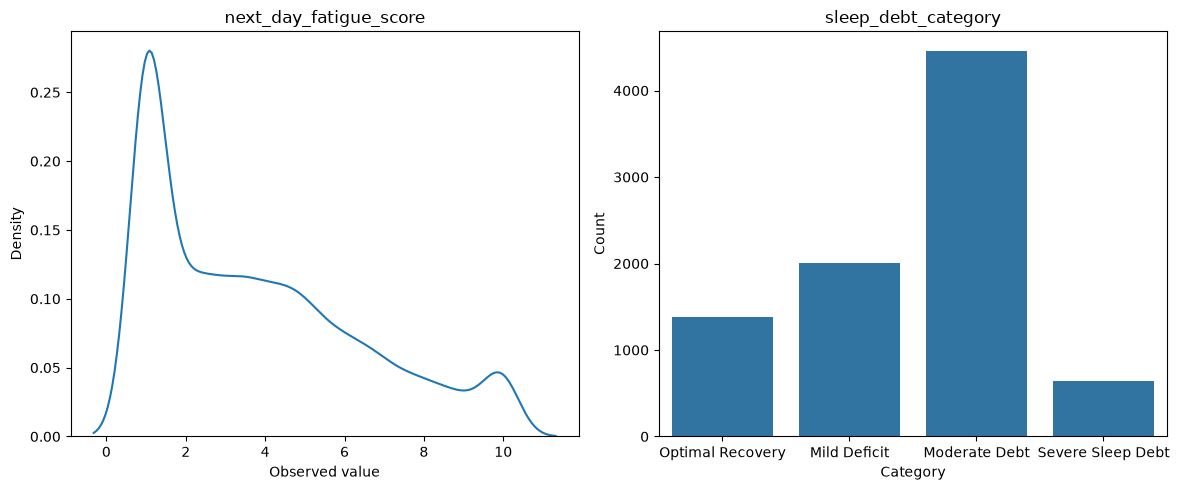

In [11]:

print('Visualizing distributions of next_day_fatigue_score and sleep_debt_category')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.kdeplot(data=sleep_data, x="next_day_fatigue_score", ax=axes[0])
axes[0].set(title="next_day_fatigue_score", xlabel="Observed value", ylabel="Density")

sns.countplot(data=sleep_data, x="sleep_debt_category", order=ordinal_ranking, ax=axes[1])
axes[1].set(title="sleep_debt_category", xlabel="Category", ylabel="Count")

plt.tight_layout()
plt.show()


Now, I'm moving on to look at the distributions of deep_sleep_pct and rem_sleep_pct. These are two other unique features to this dataset. They're sort of proxy measures of sleep quality, and understanding their distributions can give us insights into the overall sleep patterns of the users.


Showing the distributions of deep_sleep_pct and rem_sleep_pct


column,deep_sleep_pct,rem_sleep_pct
count,8500.000000,8500.000000
mean,21.735741,19.105859
std,3.069377,2.546459
min,8.100000,9.600000
25%,19.700000,17.400000
50%,21.900000,19.100000
75%,23.900000,20.800000
max,28.000000,27.000000


Making histograms for deep_sleep_pct and rem_sleep_pct


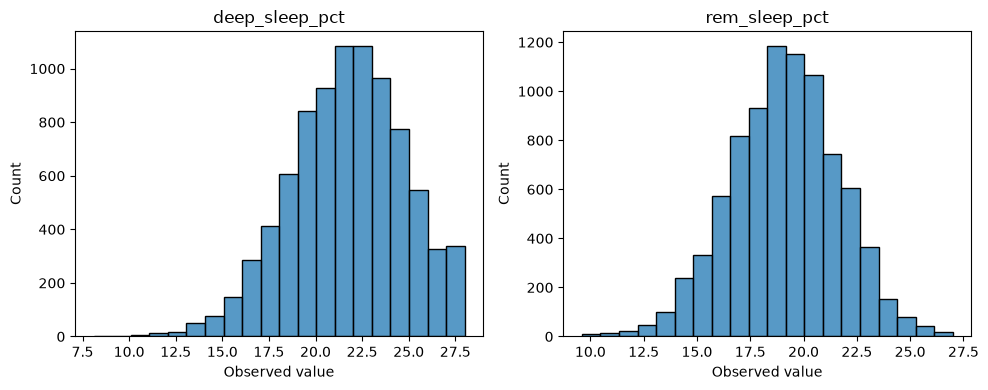

In [12]:
print('Showing the distributions of deep_sleep_pct and rem_sleep_pct')
display(sleep_data[["deep_sleep_pct", "rem_sleep_pct"]].describe())


print('Making histograms for deep_sleep_pct and rem_sleep_pct')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, column in zip(axes, ["deep_sleep_pct", "rem_sleep_pct"]):
    sns.histplot(data=sleep_data, x=column, bins=20, ax=ax)
    ax.set(title=column, xlabel="Observed value", ylabel="Count")

plt.tight_layout()
plt.show()

They both have a roughly bell shaped distribution, which is what I would have guessed without knowing anything about the actual data.

However, the deep_sleep_pct does almost look like it was clipped on the right side, where the distribution looks normally distributed up until the 25.0 value on the x-axis, and then suddenly it seems like all values above that are equally likely, until it reaches the maximum value of 28%.

In the next cell, I look at the percentiles above the 90th percentiles, we can see it basically just gradually increases at a steady rate, increasing about .2-.4 percentage points each percentile increase. So that seems odd.

My first thought seeing the graph was that maybe there had been some transformation where just any value above 28 had been replaced with 28, but if that were the case, we wouldn't see the gradual increase in the percentiles above 90. It would just look like a normal curve, with a random huge spike at the end. So, without knowing exactly how the synthetic data was generated, and not knowing enough about this domain, at this point it is difficult to draw a definitive conclusion about why the distribution looks this way.

In [13]:
print('Examining the strange lack of a right tail in deep_sleep_pct')
display(sleep_data[["deep_sleep_pct"]].describe(percentiles=np.arange(.9, 1, 0.01)))


Examining the strange lack of a right tail in deep_sleep_pct


column,deep_sleep_pct
count,8500.000000
mean,21.735741
std,3.069377
min,8.100000
90%,25.600000
91%,25.800000
92%,26.000000
93%,26.200000
94%,26.500000
95%,26.700000


In addition to the histograms, density plots can help us better understand the shape of the distributions, especially in the tails. So the density plots of deep_sleep_pct and rem_sleep_pct are shown below.

Showing the density plots of deep_sleep_pct and rem_sleep_pct


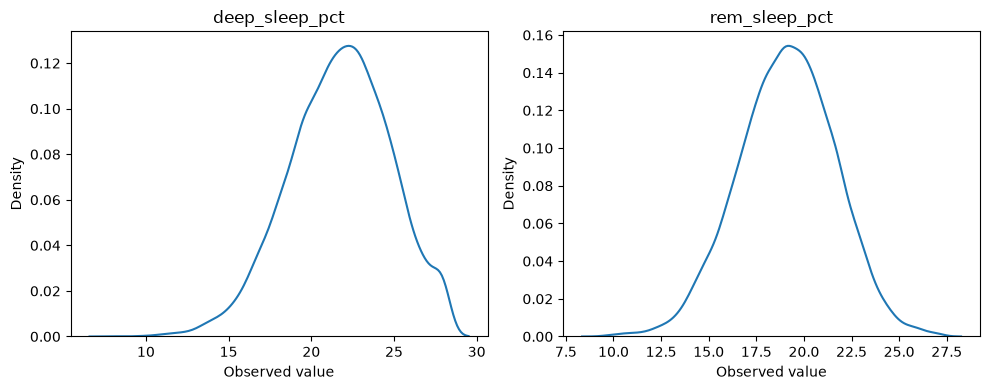

In [14]:
print('Showing the density plots of deep_sleep_pct and rem_sleep_pct')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.kdeplot(data=sleep_data, x="deep_sleep_pct", ax=axes[0])
axes[0].set(title="deep_sleep_pct", xlabel="Observed value", ylabel="Density")

sns.kdeplot(data=sleep_data, x="rem_sleep_pct", ax=axes[1])
axes[1].set(title="rem_sleep_pct", xlabel="Observed value", ylabel="Density")

plt.tight_layout()
plt.show()

The effect at the top end of deep_sleep_pct is less visible here, but still a noticeable deviation from a perfect bell curve.

The other thing I noticed is just how almost perfectly bell shaped the rem_sleep_pct distribution is. 8500 is quite a few observations, but distributions made from messy real-world data often have more irregularities, so it does sort of make it seem like the synthetic data was carefully generated to follow a normal distribution, which does sort of bring me back to wondering how useful this dataset might be for studying real-world sleep patterns.

## 4. Relationships

*(Question set 10–11.)* The two or three most important relationships, shown and interpreted — and what's surprising.

I'm digging into the seeming discrepancy between next_day_fatigue_score and sleep_debt_category I had noticed earlier.

When I had looked at plots for these 2 variables earlier, the plots looked quite different, which initially seemed puzzling. So I wanted to examine the relationship more closely by grouping the density plots of next_day_fatigue_score by sleep_debt_category.

So the density plots of next_day_fatigue_score, grouped by sleep_debt_category, are shown below.


Showing the density plots of next_day_fatigue_score by sleep_debt_category


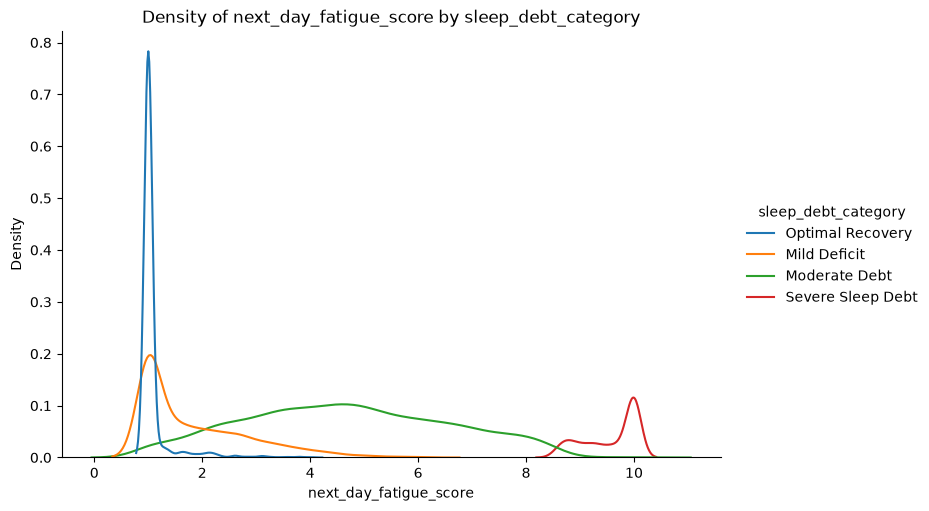

In [15]:
print('Showing the density plots of next_day_fatigue_score by sleep_debt_category')
sns.displot(data=sleep_data, x="next_day_fatigue_score", hue="sleep_debt_category", kind="kde", height=5, aspect=1.5, hue_order=ordinal_ranking)
plt.title("Density of next_day_fatigue_score by sleep_debt_category")
plt.xlabel("next_day_fatigue_score")
plt.ylabel("Density")
plt.show()

Looking at the plot, it clarifies things greatly, and makes the initial plots make sense.

Basically everybody who was classified as having optimal recovery reported a fatigue score of 1, and a fair amount of those with Mild deficit did as well. And almost nobody with a moderate deficit reported a fatigue score of 1, and it seems like most people with severe sleep debt reported very high fatigue scores (8+).

So this helps explain why the other two plots looked the way they did. Everyone in the optimal recovery category reported a fatigue score of 1, whereas those in other categories gave more varied answers, so even though more people were in those categories, the density at each point was lower.


#### Moving on to look at deep_sleep_pct and rem_sleep_pct now.

deep_sleep_pct and rem_sleep_pct are the 2 main continuous measurements I've been looking at, so I wanted to see how they relate to each other. Based on the names, my assumption was that they would both be indicators of a good night's sleep, and would therefore be positively correlated.

So I explore this by making a scatter plot of the two variables, and also just computing the correlation coefficient.

The correlation between deep_sleep_pct and rem_sleep_pct is: 0.1653351231423188

Visualizing the relationship between deep_sleep_pct and rem_sleep_pct


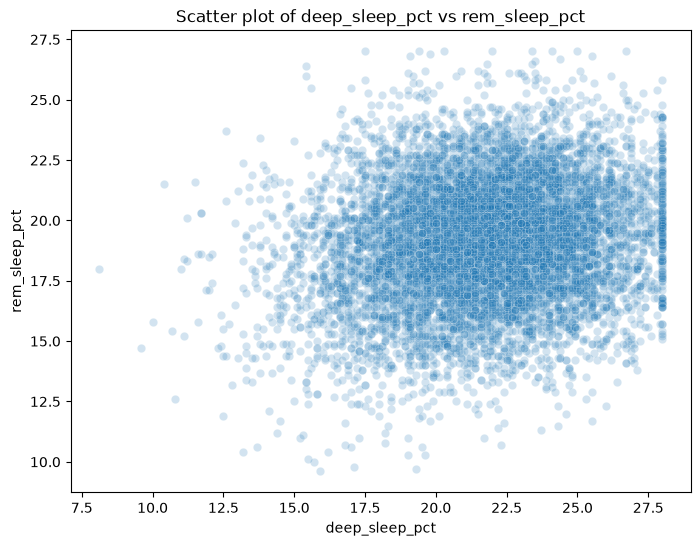

In [16]:
print('The correlation between deep_sleep_pct and rem_sleep_pct is:',
      sleep_data[['deep_sleep_pct', 'rem_sleep_pct']].corr().iloc[0, 1])
print()
print('Visualizing the relationship between deep_sleep_pct and rem_sleep_pct')
plt.figure(figsize=(8, 6))
sns.scatterplot(data=sleep_data, x="deep_sleep_pct", y="rem_sleep_pct", alpha=0.2)
plt.title("Scatter plot of deep_sleep_pct vs rem_sleep_pct")
plt.xlabel("deep_sleep_pct")
plt.ylabel("rem_sleep_pct")
plt.show()

So despite my previous assumption, deep sleep and REM sleep percentages are not strongly correlated at all. The correlation is slightly positive, at 0.165, which isn't nothing, but it's quite small. And in the plot, it bascially backs this up, because there does seem to be a slight upward slope, but again, nothing major.

So, now I'm going to look at the relationships between the continuous variables and the sleep_debt_category.

In theory, sleep_debt_category is one of the main outcome variables relating to sleep quality, so we'd expect to see some differences in the values of deep_sleep_pct and rem_sleep_pct across sleep_debt_category categories.

To do this, we look at box plots for each of the categories.

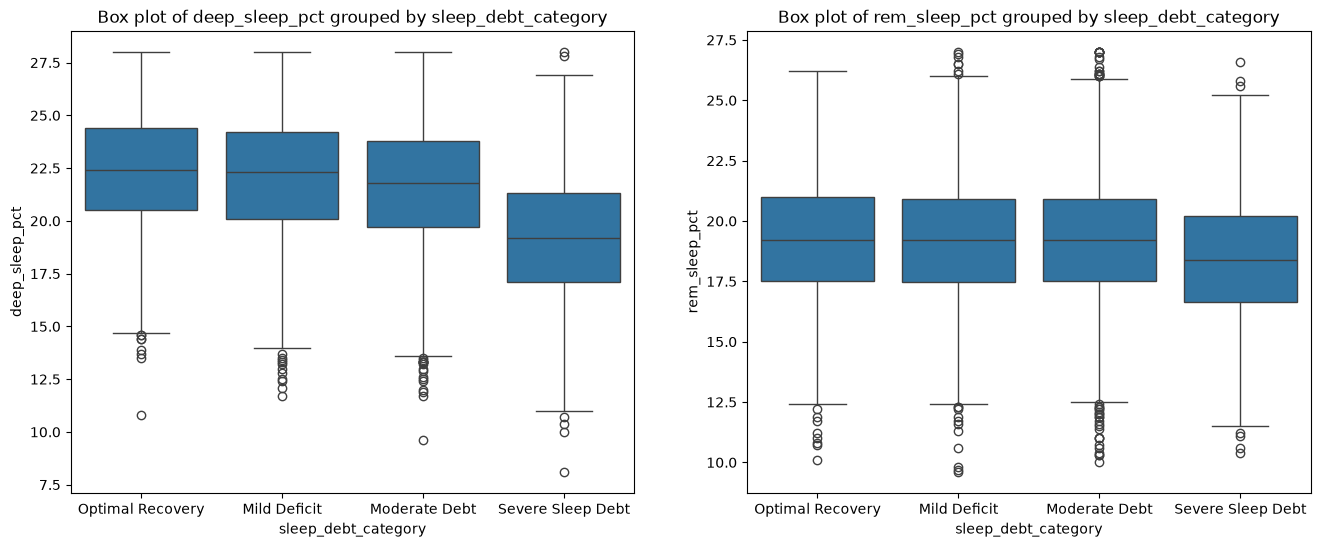

In [17]:
plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
sns.boxplot(
    data=sleep_data,
    x="sleep_debt_category",
    y="deep_sleep_pct",
    order=ordinal_ranking
)
plt.title("Box plot of deep_sleep_pct grouped by sleep_debt_category")
plt.xlabel("sleep_debt_category")
plt.ylabel("deep_sleep_pct")

plt.subplot(1, 2, 2)
sns.boxplot(
    data=sleep_data,
    x="sleep_debt_category",
    y="rem_sleep_pct",
    order=ordinal_ranking
)
plt.title("Box plot of rem_sleep_pct grouped by sleep_debt_category")
plt.xlabel("sleep_debt_category")
plt.ylabel("rem_sleep_pct")

plt.show()

So basically, the main takeaway here is that deep_sleep_pct and rem_sleep_pct both seem to be lower for the Severe Sleep Debt category, but otherwise, they don't really vary much across the other categories.

Given the findings above, it seems unlikely that deep_sleep_pct or rem_sleep_pct would have a strong correlation with next_day_fatigue_score, even though intuitively I would have assumed that they would. But, it seems worth looking into, instead of just assuming.

So first, I just looked at the correlation coefficients between those 2 variables and next_day_fatiuge_score, and got -0.341399 and -0.114575 for deep_sleep_pct and rem_sleep_pct, respectively. So, not hugely correlated, but somewhat at least, and much more strongly for deep_sleep_pct.

next_day_fatigue_score is reported in 0.1 increments, so we can actually just group by it, and get the average value for deep_sleep_pct at each of the 0.1 increments, and plot that, to get a clear picture of how deep_sleep_pct varies as next_day_fatigue_score varies.

I have the y-axis scaled to run from the min value to the max value of the original data, to show the magnitude of any change that occurs in the grouped average values.

And I make this kind of plot for both deep_sleep_pct and rem_sleep_pct.

Showing the correlation coefficients:


column
deep_sleep_pct           -0.341399
rem_sleep_pct            -0.114575
next_day_fatigue_score    1.000000
Name: next_day_fatigue_score, dtype: float64

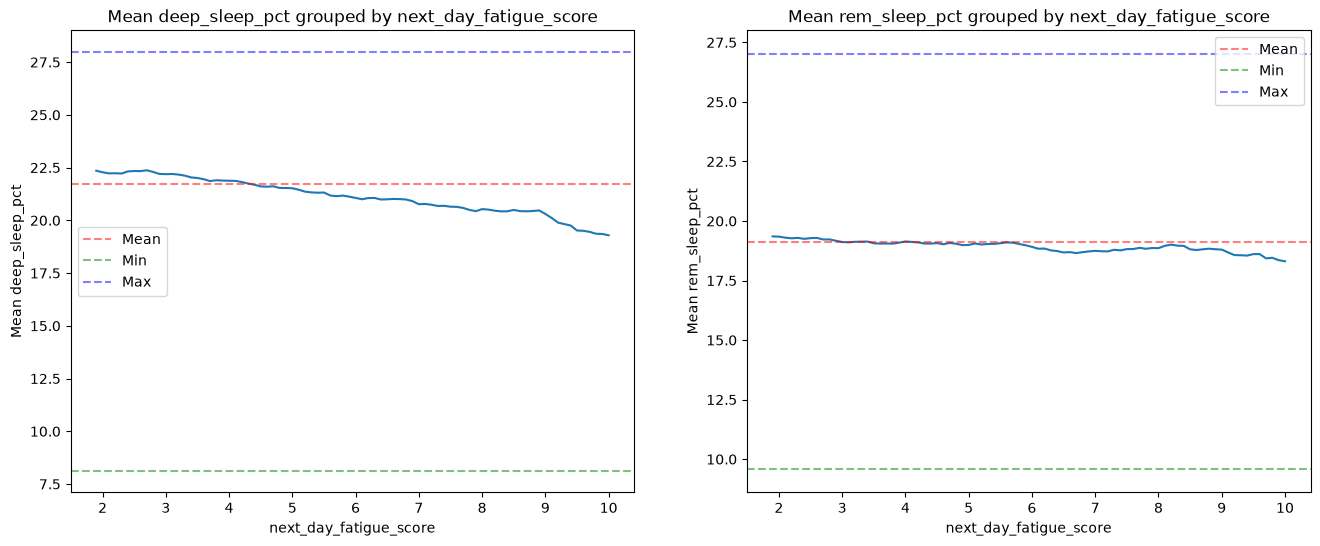

In [ ]:
# Grouping by next_day_fatigue_score and plotting the mean of
# deep_sleep_pct and rem_sleep_pct in separate line plots.
# Adding some smoothing as well to remove the noise.

print('Showing the correlation coefficients:')
display(
    sleep_data
    [['deep_sleep_pct', 'rem_sleep_pct', 'next_day_fatigue_score']]
    .corr()
    ['next_day_fatigue_score']
)
print()

grouped_means = (
    sleep_data
    .groupby('next_day_fatigue_score')
    [['deep_sleep_pct', 'rem_sleep_pct']]
    .mean()
)

plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
plt.plot(grouped_means['deep_sleep_pct'].rolling(window=10).mean())
plt.axhline(sleep_data['deep_sleep_pct'].mean(), color='r', linestyle='--', label='Mean', alpha=.50)
plt.axhline(sleep_data['deep_sleep_pct'].min(), color='g', linestyle='--', label='Min', alpha=.50)
plt.axhline(sleep_data['deep_sleep_pct'].max(), color='b', linestyle='--', label='Max', alpha=.50)
plt.legend()
plt.title("Mean deep_sleep_pct grouped by next_day_fatigue_score")
plt.xlabel("next_day_fatigue_score")
plt.ylabel("Mean deep_sleep_pct")
plt.ylim(sleep_data['deep_sleep_pct'].min() - 1, sleep_data['deep_sleep_pct'].max() + 1)

plt.subplot(1, 2, 2)
plt.plot(grouped_means['rem_sleep_pct'].rolling(window=10).mean())
plt.axhline(sleep_data['rem_sleep_pct'].mean(), color='r', linestyle='--', label='Mean', alpha=.50)
plt.axhline(sleep_data['rem_sleep_pct'].min(), color='g', linestyle='--', label='Min', alpha=.50)
plt.axhline(sleep_data['rem_sleep_pct'].max(), color='b', linestyle='--', label='Max', alpha=.50)
plt.legend()
plt.title("Mean rem_sleep_pct grouped by next_day_fatigue_score")
plt.xlabel("next_day_fatigue_score")
plt.ylabel("Mean rem_sleep_pct")
plt.ylim(sleep_data['rem_sleep_pct'].min() - 1, sleep_data['rem_sleep_pct'].max() + 1)

plt.show()

And looking at the plots, it matches up with the correlation coefficients we saw. They're both clearly negative, and much more strongly so in the case of deep_sleep_pct. But, seeing how closely the average values at all fatigue_score are to the mean, helps illustrate the point that the correlation isn't all that big.

## 5. Readiness

*(Question set 12–13.)* If an analyst wanted to run an analysis tomorrow, what would they still have to do? What analyses is this dataset ready to support?

12. If I wanted to run an analysis tomorrow, what would I still have to do to this data?

    I think the data itself is basically ready to be used. None of the columns have missing values, and all of the values seem reasonable. The variables are all already being treated as the correct dtypes.

    The main thing outstanding is just getting some questions about data provenance answered. The fact that it's synthetic data is theoretically okay as a starting point to identify questions you'd want to explore further by collecting your own data. But, almost no information is really given about how the data was generated, and so we're left to just hope and assume that the generation process was executed well, and that the data actually is representative. And so it's hard to really know if, when we see a pattern, or even don't see a pattern we expected, if we can interpret anything from that other than that it was a quirk of the data generation process.


13. What analyses is this dataset ready to support?

    It's ready for basically any analysis you want to do with this data, just with the understanding that any results should not be interpreted as applying outside the context of this dataset.

## 6. Your questions (14, 15, …)

The dataset-specific questions this dataset forces that the starter set doesn't ask — at least two, numbered, with your answers. These join your personal EDA guide and travel with you to Module 6 and the final project.

My question 14 would be:
    
    Does any part of your data look too clean? Why might this be, and what implications might it have on your analysis?

And the answer is that, in my earlier analysis, I had looked at the density plot of rem_sleep_pct, and it really does just seem too perfect, which raises questions about how exactly the data was created. It's just one of many such questions in this data that might affect the validity of any conclusions drawn from it, and there's no real good way to verify it without more information about the data collection process. The density plot of rem_sleep_pct is reproduced below.

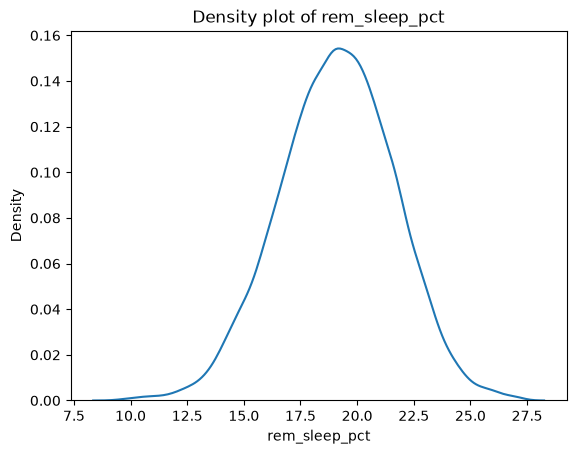

In [19]:
# Show the density plot of rem_sleep_pct
sns.kdeplot(
    data=sleep_data,
    x="rem_sleep_pct",
)
plt.title("Density plot of rem_sleep_pct")
plt.xlabel("rem_sleep_pct")
plt.ylabel("Density")
plt.show()


My question 15:

    Another data provenance question, but for data like this, where some of it is self report, and other data is telemtry data, gathered by a machine, which columns are based on self report, and which are telemetry. 

Unfortunately, in this dataset, we don't have that data, but it would definitely affect how we interpret the results. Self report can be less accurate or biased in some cases, but also, if we're trying to understand how various sleep habits affect subjective experiences like fatigue, self report is almost more important than whether a machine reports that you should be feeling tired or not. So yeah, it's important to know, but all we really can do is guess with this data set.


## Reflection

A few paragraphs (see the README): what was confusing and how you resolved it; where AI helped; one suggestion you verified, corrected, narrowed, or rejected and how you checked it; what you can now explain or do without AI that you couldn't before; how long it took; and any unresolved questions. If you did not use AI, explain how you found help and verified your work instead.

I kind of noticed later than I should have that the provenance portion of my dataset was very lacking. It seemed to have good column descriptions on Kaggle, with plenty of upvotes, and as I got going, I realized it said it was synthetic, and didn't give any info on how the data was generated. So I was left kind of not knowing if that was just like a way of anonymizing the data, but where the data would basically have the same kinds of relationsships amongst the variables, and same distributions within them, via some sort of oversampling method, or if the data for each variable was just independently made by like sampling from a normal distribution based on some existing dataset's mean and std. So I guess I was slightly confused how to handle/think about this. Realistically, I maybe should have just thrown it out and picked again, but I went forward with it, trying to be honest about the limitations this added.

AI was very helpful with the plotting, and getting summary stats generated quickly. It was less helpful in terms of how to structure my overall approach, or like in terms of choosing which variables were the most important. And the inline suggestions when I was typing my interpretations and thoughts were a bit annoying, because partially, I wanted to think through what I was typing on my own, but also, its suggestions were honestly usually either not true, or not actually a helpful thing to note.

Um, I'm not sure there's anything I can now explain or do without AI that I couldn't before. So maybe I wasn't using it as much as I should have, or at least not asking it enough questions. I mostly just asked it to do things, things I either could already do, just more slowly, or things like plots, where I'd definitely have to look it up if I wanted to make them without AI.

The assignment took me about 3.5 hours to finish.
